# Get Solar Energy Landscape Prior Land Use
* Still need to incorporate the CDL [cultivated layer logic](https://www.nass.usda.gov/Research_and_Science/Cropland/sarsfaqs2.php#common.18) here where: _The Cultivated Layer is based on the most recent five years of CDL data and is updated annually. An Erdas Imagine Spatial Model is used to create the Cultivated Layer. The processing logic is as follows. If a pixel is identified as cultivated in at least two out of the five years of CDL data then it is assigned to the 'Cultivated' category. The exception is that all pixels identified as cultivated in the most recent year are assigned to the 'Cultivated' category regardless of whether or not they were cultivated in the previous four years of CDL data._

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import geopandas as gpd
import os 
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Import gmseusUtils
import gmseusUtils as gu

## Set paths and helper functions

In [2]:
# Set folder paths
wd = r'S:\Users\stidjaco\R_files\BigPanel'
downloaded_path = os.path.join(wd, r'Data\Downloaded')
derived_path = os.path.join(wd, r'Data\Derived')
derivedTemp_path = os.path.join(derived_path, r'intermediateProducts')
figures_path = os.path.join(wd, r'Figures')

# Set initial GM-SEUS path
arraysPath = os.path.join(derived_path, r'GMSEUS/SHP/GMSEUS_Arrays_Final_2025_v2_0.shp')

# Set LULC base path
lulcBaseFolder = os.path.join(derivedTemp_path, r'geeLULC')

# Set aoi path
aoiPath = os.path.join(downloaded_path, r'CONUS_NoGreatLakes\CONUS_No_Great_Lakes.shp')

# Set USPVDB path (contains facility type -- landfill, brownfield prior land use information)
uspvdbPath = os.path.join(downloaded_path, r'SolarDB\USPVDB\uspvdb_v3_0_20250430.shp')

# Set paths to class schema files
lulc_schema_path = os.path.join(wd, r'Data\Downloaded\LULCschema')

# Set landcover bounds
cdl_bnds = [2008, 2024]

# Set plot CRS
# plotCRS = '5070'

# Set some colors 
darkGreyTheme = '#3D3D3D'

# Set NaN value
lulcNaN = np.nan

# Set important columns
IDcol = 'arrayID'
LULCcol = 'priorLULC'

# Load the config from the text file
config = gu.load_config()

# Set general variables
currentVersion = config['currentVersion'] # version of the dataset
gee_crs = config['gee_crs'] # native projection of Google Earth Engine exports
toCRS = config['to_crs']  # EPSG:6350 NAD83 (2011)

# Append toCRS with the EPSG prefix for use in GeoPandas
toCRS = f'EPSG:{toCRS}'

# Define colors for pie chart (same as area plot)
landuse_colors = {'Cropland': 'orange', 'Natural': 'forestgreen', 'Other LULC': 'darkgrey'}

# TEMP

In [34]:
# Call gmseus 
gmseus = gpd.read_file(arraysPath)

# Print number of arrays and total capacity (capMWDC) of arrays with caapcity less than 1 MWDC
commScale = gmseus[gmseus['capMWDC'] < 1]
num_arrays = len(commScale)
total_capacity = commScale['capMWDC'].sum()
print(f'Number of arrays with capacity less than 1 MWDC: {num_arrays}')
print(f'Total capacity of arrays with capacity less than 1 MWDC: {total_capacity} MWDC')

Number of arrays with capacity less than 1 MWDC: 7823
Total capacity of arrays with capacity less than 1 MWDC: 2479.8590000000004 MWDC


In [33]:
# Set form 860 location folder
form860Folder = os.path.join(downloaded_path, r'Form860_Solar')

# Call the 2024 excel file, select the Operable tab, and skip the first row which contains the title of the sheet. This will give you a DataFrame with the relevant data for solar arrays in 2024.
form860_2024 = pd.read_excel(os.path.join(form860Folder, r'3_3_Solar_Y2024.xlsx'), sheet_name='Operable', header=1)

# Select rows where any column with 'Thin-Film in the title contains "Y"
thin_film_columns = [col for col in form860_2024.columns if 'Thin-Film' in col]
thin_film_arrays_2024 = form860_2024[form860_2024[thin_film_columns].apply(lambda row: row.astype(str).str.contains('Y').any(), axis=1)]

# For each year (Operating Year) I want to know the total number of arrays and proportion of "Nameplate Capacity (MW)" for each Thin-Film type (Thin-Film (CdTe)?, Thin-Film (A-Si)?, Thin-Film (CIGS)?, Thin-Film (Other)?). This is set up in that all rows have each thin film type column and if the array is that type, it is marked with a "Y". So, for each year, I want to count the number of arrays that have a "Y" in each thin film type column and sum the "Nameplate Capacity (MW)" for those arrays. Then, I want to calculate the proportion of the total capacity for each thin film type for that year.
# Group by Operating Year and calculate total number of arrays and total capacity for each thin film type
thin_film_stats = thin_film_arrays_2024.groupby('Operating Year').apply(lambda x: pd.Series({
    'Total Arrays': len(x),
    'CdTeArrays': x[x['Thin-Film (CdTe)?'] == 'Y'].shape[0],
    'A-SiArrays': x[x['Thin-Film (A-Si)?'] == 'Y'].shape[0],
    'CIGSArrays': x[x['Thin-Film (CIGS)?'] == 'Y'].shape[0],
    'Other Thin-Film Arrays': x[x['Thin-Film (Other)?'] == 'Y'].shape[0],
    'CdTe Capacity': x[x['Thin-Film (CdTe)?'] == 'Y']['Nameplate Capacity (MW)'].sum(),
    'A-Si Capacity': x[x['Thin-Film (A-Si)?'] == 'Y']['Nameplate Capacity (MW)'].sum(),
    'CIGS Capacity': x[x['Thin-Film (CIGS)?'] == 'Y']['Nameplate Capacity (MW)'].sum(),
    'Other Thin-Film Capacity': x[x['Thin-Film (Other)?'] == 'Y']['Nameplate Capacity (MW)'].sum()
}))

# Calculate total capacity for each year
thin_film_stats['Total Capacity'] = thin_film_stats['CdTe Capacity'] + thin_film_stats['A-Si Capacity'] + thin_film_stats['CIGS Capacity'] + thin_film_stats['Other Thin-Film Capacity']

# Calculate proportion of total capacity for each thin film type
thin_film_stats['CdTe Proportion'] = thin_film_stats['CdTe Capacity'] / thin_film_stats['Total Capacity']
thin_film_stats['A-Si Proportion'] = thin_film_stats['A-Si Capacity'] / thin_film_stats['Total Capacity']
thin_film_stats['CIGS Proportion'] = thin_film_stats['CIGS Capacity'] / thin_film_stats['Total Capacity']
thin_film_stats['Other Thin-Film Proportion'] = thin_film_stats['Other Thin-Film Capacity'] / thin_film_stats['Total Capacity']

# Get proportion of arrays that are each thin film type
thin_film_stats['CdTe Array Proportion'] = thin_film_stats['CdTeArrays'] / thin_film_stats['Total Arrays']
thin_film_stats['A-Si Array Proportion'] = thin_film_stats['A-SiArrays'] / thin_film_stats['Total Arrays']
thin_film_stats['CIGS Array Proportion'] = thin_film_stats['CIGSArrays'] / thin_film_stats['Total Arrays']
thin_film_stats['Other Thin-Film Array Proportion'] = thin_film_stats['Other Thin-Film Arrays'] / thin_film_stats['Total Arrays']

# Reset index, and print operating year, total capacity, and CdTe proportion
thin_film_stats = thin_film_stats.reset_index()
print(thin_film_stats[['Operating Year', 'Total Capacity', 'Total Arrays','CdTe Proportion', 'CdTe Array Proportion']]) 

# Now, get the total proportion of CdTe capacity across all years
total_cdte_capacity = thin_film_stats['CdTe Capacity'].sum()
total_capacity = thin_film_stats['Total Capacity'].sum()
total_cdte_proportion = total_cdte_capacity / total_capacity if total_capacity != 0 else 0
print(f"Total CdTe Proportion across all years: {total_cdte_proportion:.2%}")

# Get total proortion of CdTe arrays across all years
total_cdte_arrays = thin_film_stats['CdTeArrays'].sum()
total_arrays = thin_film_stats['Total Arrays'].sum()
total_cdte_array_proportion = total_cdte_arrays / total_arrays if total_arrays != 0 else 0
print(f"Total CdTe Array Proportion across all years: {total_cdte_array_proportion:.2%}")

    Operating Year  Total Capacity  Total Arrays  CdTe Proportion  \
0             2008            11.0           2.0         1.000000   
1             2009            25.9           6.0         1.000000   
2             2010           122.4          12.0         0.962418   
3             2011           140.4          22.0         0.591168   
4             2012           527.7          13.0         0.954141   
5             2013          1203.1          25.0         0.981465   
6             2014          1353.0          43.0         0.998522   
7             2015           961.2          55.0         0.947566   
8             2016          1553.2          77.0         0.971349   
9             2017           865.9          83.0         0.950572   
10            2018          1203.3          81.0         0.791573   
11            2019          1784.1          63.0         0.987949   
12            2020          2522.4          65.0         0.986957   
13            2021          4101.2

C:\Users\stidjaco\AppData\Local\Temp\ipykernel_36764\2800480817.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  thin_film_stats = thin_film_arrays_2024.groupby('Operating Year').apply(lambda x: pd.Series({


## Process LULC Outputs from GEE

In [ ]:
# Get all csv files in lulc folder and concatenate them
lulc_files = [f for f in os.listdir(lulcBaseFolder) if f.endswith('.csv')]
lulc = pd.concat([pd.read_csv(os.path.join(lulcBaseFolder, f)) for f in lulc_files], ignore_index=True)

# Call GMSEUS arrays shapefile
arrays = gpd.read_file(arraysPath)

# Choose grouping columns
groupCol = 'crop9Class' # crop9class, MajorClass

# Call schema files
na_schema = pd.read_csv(na_schema_path)

# Fill missing LULC values with NaN
lulc[LULCcol] = lulc[LULCcol].replace(-9999, lulcNaN)

# In each LULC row, fill slice with NaN if year is outside bounds of LULC maps
# For example, if instYr is 2010, and cdl_bnds are [2008, 2023], then fill cdl columsn for that row with NaN if yr_prioor is 3 or greater (3 years before 2010 is 2007, meaning we dont have data starting at 2007)
# lulc['cdl'] = lulc.apply(lambda x: x['cdl'] if x['yr_prior'] <= x['instYr'] - cdl_bnds[0] else lulcNaN, axis=1)

# Ensure sorting before grouping
lulc_sorted = lulc.sort_values(by=[IDcol,'yr_prior'])

# Group by ID column, aggregating as lists first
lulc_grouped = lulc_sorted.groupby(IDcol).agg({
    LULCcol: list,        # Aggregate as list\
    'instYr': 'first',  # Ensure a single value
}).reset_index()

# Convert lists to NumPy arrays for efficient slicing
lulc_grouped[LULCcol] = lulc_grouped[LULCcol].apply(np.array)

# Join LULC data with arrays to get metadata
lulc_grouped = lulc_grouped.merge(arrays[[IDcol, 'nativeID']], on=IDcol, how='left') 
lulc_grouped = lulc_grouped.merge(arrays[[IDcol, 'NAM_0']], on=IDcol, how='left') 
lulc_grouped = lulc_grouped.merge(arrays[[IDcol, 'area']], on=IDcol, how='left') 
lulc_grouped = lulc_grouped.merge(arrays[[IDcol, 'capMWDC']], on=IDcol, how='left') 

# For each product, create a new column (e.g., cdlGMSEUSclass, lcmapGMSEUSclass, etc.) that maps the value in lulc_grouped to the corresponding gmseusClass in the schema by matching the value in the product to the value in the schema's 'Value' column
lulc_grouped['crop9Class'] = lulc_grouped[LULCcol].apply(lambda x: gu.mapClass(x, na_schema, 'crop9'))
lulc_grouped['MajorClass'] = lulc_grouped[LULCcol].apply(lambda x: gu.mapClass(x, na_schema, 'MajorClass'))

# Do some bonus groupings for AGU
# Within crop9Class, group 'Grapes' and 'Orchards' into 'Grapes and Orchards'
# Within MajorClass, group 'Grassland/Pasture' into cropland
lulc_grouped['crop9Class'] = lulc_grouped['crop9Class'].apply(lambda x: np.array(['Grapes and Orchards' if val in ['Grapes', 'Orchards'] else val for val in x], dtype=object))
lulc_grouped['MajorClass'] = lulc_grouped['MajorClass'].apply(lambda x: np.array(['Cropland' if val == 'Grassland/Pasture' else val for val in x], dtype=object))

# Get the most common land use type (mode) for each arrayID
lulc_grouped['priorLULC'] = lulc_grouped[groupCol].apply(lambda x: gu.mostCommonLandUse(x))

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Get Other LULC from USPVDB

# Call uspvdb shapefile
uspvdb = gpd.read_file(uspvdbPath)

# Transform uspvdb to toCRS
uspvdb = uspvdb.to_crs(toCRS)

# Set a new column that is uspvdbLULC that is based on p_type
# If p_type is 'superfund', 'AML', 'PCSC', 'landfill', 'RCRA', or 'landfill-named', set LULC column to 'Other LULC'
uspvdb['uspvdbLULC'] = uspvdb.apply(lambda x: 'Other LULC' if x['p_type'] in ['superfund', 'AML', 'PCSC', 'landfill', 'RCRA', 'landfill-named'] else x['p_type'], axis=1)

# Drop all rows where uspvdbLULC is not 'Other LULC'
uspvdbOtherLULC = uspvdb[uspvdb['uspvdbLULC'] == 'Other LULC'].copy()

# Spatial join between arrays and uspvdbOtherLULC
arraysOtherLULC = gpd.sjoin(arrays, uspvdbOtherLULC[['uspvdbLULC', 'geometry']], how='left', predicate='intersects')
lulc_grouped = lulc_grouped.merge(arraysOtherLULC[[IDcol, 'uspvdbLULC']], on=IDcol, how='left')

# If uspdbLULC is 'Other LULC', set priorLULC to 'Other LULC', else keep priorLULC as is
lulc_grouped['priorLULC'] = lulc_grouped.apply(lambda x: 'Other LULC' if x['uspvdbLULC'] == 'Other LULC' else x['priorLULC'], axis=1)
lulc_grouped = lulc_grouped.drop(columns=['uspvdbLULC'], errors='ignore')

# Print value counts of the cdlLandUse column
print("Most Common LULC Class Counts:")
print(lulc_grouped['priorLULC'].value_counts())

# Join cdlLandUse with original GMSEUS gdf
arraysLULC = arrays.merge(lulc_grouped[[IDcol, 'priorLULC']], on=IDcol, how='left')

# Drop index_right 
arraysLULC = arraysLULC.drop(columns=['index_right'], errors='ignore')

# Save the GMSEUS arrays shapefile with cdlLandUse
arraysLULC.to_file(os.path.join(derivedTemp_path, r'NA_arrays_LULC.shp'), driver='ESRI Shapefile')

Most Common LULC Class Counts:
priorLULC
Other LULC             9448
Hay/Pasture            4880
Grain                  4742
Natural                4490
Other Crops             844
Grapes and Orchards     614
Cotton                  236
Vegetables               56
Name: count, dtype: int64


## Prepare kcal per m2 and mm per year for food and water analysis

In [10]:
# Call arraysLULC
arraysLULC = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_LULC.shp'))

# Call irrig presence data (for now, we only look one year prior, so theres no need to aggregate)
irrig_files = [f for f in os.listdir(irrigBaseFolder) if f.endswith('.csv')]
irrig = pd.concat([pd.read_csv(os.path.join(irrigBaseFolder, f)) for f in irrig_files], ignore_index=True)

# Join cdlLandUse with original GMSEUS gdf
arraysLULC = arraysLULC.merge(irrig[[IDcol, 'irrig']], on=IDcol, how='left')

# Subset for all rows where priorLULC is not 'Natural' or 'Other LULC'
arraysColocated = arraysLULC[~arraysLULC['priorLULC'].isin(['Natural', 'Other LULC'])].reset_index(drop=True)

# Call kcal, irrig, and CDL data
Nass_Classifications = pd.read_csv(Nass_Classification_path)
kcal_m2 = pd.read_csv(kcal_m2_path)
mm_yr = pd.read_csv(mm_yr_path)
operational_cost = pd.read_csv(operational_cost_path)

# ============================================================
# Universal settings
# ============================================================
IGNORE_DOUBLE_CROPS = True  # ignore "Dbl Crop ..." and irrig composites like "wheat_corn"
OTHER_BUCKET_NAME   = "Other Crops"

# ============================================================
# Helpers: normalize join keys
# ============================================================
def canon_cdl(s: pd.Series) -> pd.Series:
    """Normalize CDL-style crop names (lowercase, trim, collapse whitespace, & -> and)."""
    return (
        s.astype(str)
         .str.lower()
         .str.strip()
         .str.replace("&", "and")
         .str.replace(r"\s+", " ", regex=True)
    )

def canon_irrig(s: pd.Series) -> pd.Series:
    """Normalize irrigation crop group strings to match mm_yr Crop conventions."""
    return (
        s.astype(str)
         .str.lower()
         .str.strip()
         .str.replace("&", "and")
         .str.replace(", ", "_")
         .str.replace(" ", "_")
    )

def is_double_crop(cdl_crop: pd.Series, irrig_crop: pd.Series) -> pd.Series:
    """Identify double-crop rows (CDL 'Dbl Crop ...' or irrig composites with underscores)."""
    cdl_flag = cdl_crop.astype(str).str.contains("Dbl Crop", case=False, na=False)
    irrig_flag = canon_irrig(irrig_crop).str.contains("_", na=False)
    return cdl_flag | irrig_flag

# ============================================================
# Helpers: map irrigation group -> GMSEUS priorLULC buckets
# ============================================================
def to_priorLULC_from_irrigkey(irrig_key: str) -> str:
    if irrig_key in {"orchards", "berry_totals"}:
        return "Grapes and Orchards"
    if irrig_key in {"vegetable_totals", "lettuce", "tomatoes", "beans", "potatoes"}:
        return "Vegetables"
    if irrig_key == "cotton":
        return "Cotton"
    if irrig_key in {"hay_and_haylage", "pastureland"}:
        return "Hay/Pasture"
    if irrig_key in {"corn", "soybeans", "wheat", "small_grains", "sorghum", "rice"}:
        return "Grain"
    return OTHER_BUCKET_NAME

# ============================================================
# Clean column names (strip whitespace)
# ============================================================
for df_name in ["Nass_Classifications", "kcal_m2", "mm_yr", "arraysColocated"]:
    df = globals()[df_name]
    df.columns = [c.strip() for c in df.columns]
    globals()[df_name] = df

# ============================================================
# Standardize key columns to expected names
# ============================================================
# kcal_m2: ensure "Crop" exists (you fixed 'crop' -> 'Crop')
if "Crop" not in kcal_m2.columns:
    raise KeyError("kcal_m2 must contain a 'Crop' column (CDL crop name).")

# mm_yr: your crop group column is currently named "Crop" and Value is the mm/yr
if "Crop" not in mm_yr.columns:
    raise KeyError("mm_yr must contain a 'Crop' column (irrigation crop group).")
if "Value" not in mm_yr.columns:
    raise KeyError("mm_yr must contain a 'Value' column (mm per year).")

mm_yr = mm_yr.rename(columns={"Value": "mm_yrIrrig"}).copy()

# Nass_Classifications: must contain CDL Crop and Irrig_Crop bridge
required_bridge_cols = {"Crop", "Irrig_Crop"}
missing = required_bridge_cols - set(Nass_Classifications.columns)
if missing:
    raise KeyError(f"Nass_Classifications missing required columns: {missing}")

# arraysColocated: must contain priorLULC categories
if "priorLULC" not in arraysColocated.columns:
    raise KeyError("arraysColocated must contain a 'priorLULC' column.")

# ============================================================
# Build normalized join keys
# ============================================================
Nass_Classifications = Nass_Classifications.copy()
kcal_m2 = kcal_m2.copy()
mm_yr = mm_yr.copy()

Nass_Classifications["Crop_key"]  = canon_cdl(Nass_Classifications["Crop"])
kcal_m2["Crop_key"]              = canon_cdl(kcal_m2["Crop"])

Nass_Classifications["Irrig_key"] = canon_irrig(Nass_Classifications["Irrig_Crop"])
mm_yr["Irrig_key"]               = canon_irrig(mm_yr["Crop"])

# ============================================================
# Optionally remove double crops (per your note)
# ============================================================
bridge = Nass_Classifications[["Crop", "Crop_key", "Irrig_Crop", "Irrig_key"]].copy()

if IGNORE_DOUBLE_CROPS:
    dc_mask = is_double_crop(bridge["Crop"], bridge["Irrig_Crop"])
    bridge = bridge.loc[~dc_mask].copy()

# Drop NA-like keys
bridge = bridge.replace({"Crop_key": {"na": np.nan}, "Irrig_key": {"na": np.nan}})
bridge = bridge.dropna(subset=["Crop_key", "Irrig_key"]).drop_duplicates()

# ============================================================
# Join caloric density by CDL crop name + irrigation by irrig group
# ============================================================
crop_tbl = (
    bridge
    .merge(
        kcal_m2[["Crop_key", "kcal_per_m2"]].drop_duplicates(),
        on="Crop_key",
        how="left"
    )
    .merge(
        mm_yr[["Irrig_key", "mm_yrIrrig"]].drop_duplicates(),
        on="Irrig_key",
        how="left"
    )
)

# ============================================================
# Assign each CDL crop to a GMSEUS priorLULC bucket, defaulting to Other Crops
# ============================================================

# Map irrig_key to priorLULC using the helper function
crop_tbl["priorLULC"] = crop_tbl["Irrig_key"].apply(to_priorLULC_from_irrigkey)

# ============================================================
# Compute bucket-level averages across all relevant crops
# ============================================================

# Compute mean kcal_per_m2 and mm_yrIrrig for each priorLULC bucket
bucket_means = (
    crop_tbl
    .groupby("priorLULC", dropna=False)
    .agg(
        kcal_per_m2=("kcal_per_m2", "mean"),
        mm_yrIrrig=("mm_yrIrrig", "mean"),
        n_crops=("Crop", "nunique")
    )
    .reset_index()
)

# ============================================================
# Attach bucket means to arraysColocated via priorLULC
# ============================================================

# Merge bucket means into arraysColocated
arraysColocated = arraysColocated.merge(bucket_means, on="priorLULC", how="left")

# Rename columns for clarity
arraysColocated = arraysColocated.rename(columns={
    "kcal_per_m2": "kcal_m2",
    "mm_yrIrrig": "mm_yrIrrig"
})

# If irrig column is 0 (non-irrigated), set mm_yrIrrig to 0
arraysColocated.loc[arraysColocated['irrig'] == 0, 'mm_yrIrrig'] = 0

# Calculate total area in m2 for each array. There is no area column, so we need to calculate it using gdf geometry
arraysColocated['totArea'] = arraysColocated.geometry.area

# For each array, compute total caloric and irrigaiton offsets
arraysColocated['totkcalYr'] = arraysColocated['kcal_m2'] * arraysColocated['totArea']
arraysColocated['totm3Yr'] = arraysColocated['mm_yrIrrig'] / 1e3 * arraysColocated['totArea']

# Apply the function to create the naRegion column
arraysColocated['naRegion'] = arraysColocated['NAM_0'].apply(assign_na_region)

# Export arraysColocated
arraysColocated.to_file(os.path.join(derivedTemp_path, r'NA_arrays_colocated_withKcalIrrig.shp'), driver='ESRI Shapefile')

# ============================================================
# Diagnostics: confirm joins worked and show what's missing
# ============================================================
print("crop_tbl rows:", len(crop_tbl))
print("crop_tbl missing kcal_m2:", crop_tbl["kcal_per_m2"].isna().mean())
print("crop_tbl missing mm_yrIrrig:", crop_tbl["mm_yrIrrig"].isna().mean())
print("\nBucket means:")
print(bucket_means.sort_values("priorLULC").to_string(index=False))

# Optional: inspect top missing keys if anything is still unmapped
if crop_tbl["kcal_per_m2"].isna().any():
    print("\nTop CDL crops missing kcal_per_m2:")
    print(crop_tbl.loc[crop_tbl["kcal_per_m2"].isna(), "Crop"].value_counts().head(25).to_string())
if crop_tbl["mm_yrIrrig"].isna().any():
    print("\nTop Irrig_Crop types missing mm_yrIrrig:")
    print(crop_tbl.loc[crop_tbl["mm_yrIrrig"].isna(), "Irrig_Crop"].value_counts().head(25).to_string())

crop_tbl rows: 98
crop_tbl missing kcal_m2: 0.22448979591836735
crop_tbl missing mm_yrIrrig: 0.22448979591836735

Bucket means:
          priorLULC  kcal_per_m2  mm_yrIrrig  n_crops
             Cotton   152.558805     929.640        1
              Grain  2576.772258     763.905        8
Grapes and Orchards  1189.223670     792.480       16
        Hay/Pasture    66.918618     716.280        5
        Other Crops  1285.299145     152.400       23
         Vegetables  1855.848386     706.120        6

Top CDL crops missing kcal_per_m2:
Crop
Fallow/Idle Cropland        1
Perennial Ice/Snow          1
Woody Wetlands              1
Mixed Forest                1
Evergreen Forest            1
Deciduous Forest            1
Developed/High Intensity    1
Developed/Med Intensity     1
Developed/Low Intensity     1
Developed/Open Space        1
Open Water                  1
Forest                      1
Aquaculture                 1
Nonag/Undefined             1
Wetlands                    1
Wat

## Plot kcal per year and irrig per yera

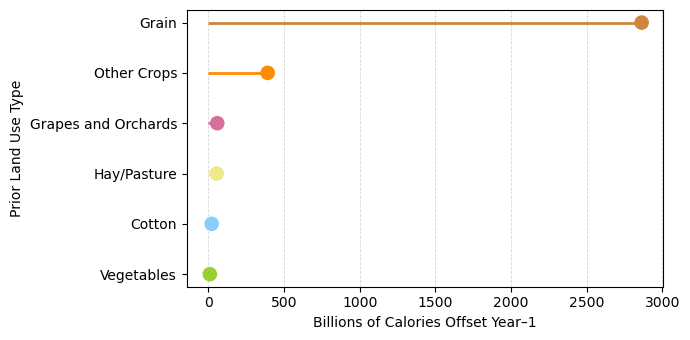

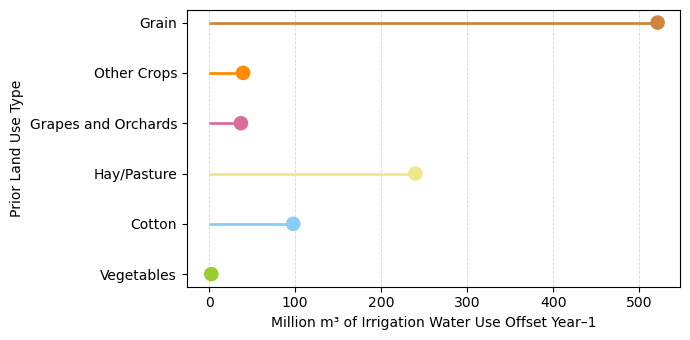

In [11]:
# Call arraysColocated with kcal and irrig
arraysColocated = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_colocated_withKcalIrrig.shp'))

# ============================================================
# Universal settings
# ============================================================

LULC_COLORS = {
    "Grapes and Orchards": "#D76E9B",
    "Cotton": "lightskyblue",
    "Other Crops": "darkorange",
    "Grain": "peru",
    "Hay/Pasture": "khaki",
    "Vegetables": "yellowgreen"
}

# ============================================================
# Function to get lollipop chart for a total impact value
# ============================================================

def plot_lollipop_chart(arrays, CAT_COL, VALUE_COL, TOP_N=None, DIV_BY=1e9, LULC_COLORS=None, xlab=''):
    cropOrder = ['Grain', 'Other Crops', 'Grapes and Orchards', 'Hay/Pasture', 'Cotton', 'Vegetables']

    # aggregate totals
    df = arrays.dropna(subset=[CAT_COL, VALUE_COL]).copy()
    tot = df.groupby(CAT_COL, as_index=False)[VALUE_COL].sum()

    # if unexpected categories exist, append them after your desired order
    extras = [c for c in tot[CAT_COL].unique() if c not in cropOrder]
    full_order = cropOrder + sorted(extras)

    # enforce order
    tot[CAT_COL] = pd.Categorical(tot[CAT_COL], categories=full_order, ordered=True)
    tot = tot.sort_values(CAT_COL)

    # optionally keep only top N by value (AFTER ordering, if you want TOP_N to mean "largest", do it before sort)
    if TOP_N is not None:
        tot = tot.sort_values(VALUE_COL, ascending=False).head(TOP_N)
        tot[CAT_COL] = pd.Categorical(tot[CAT_COL], categories=full_order, ordered=True)
        tot = tot.sort_values(CAT_COL)

    # map colors as plain strings (avoid categorical fillna issue)
    colors = tot[CAT_COL].astype(str).map(LULC_COLORS).fillna("grey")

    # plot
    fig, ax = plt.subplots(figsize=(7, max(3.5, 0.55 * len(tot))))
    y = np.arange(len(tot))
    x = tot[VALUE_COL].values / DIV_BY
    ax.hlines(y, 0, x, linewidth=2, color=colors)
    ax.scatter(x, y, s=90, color=colors, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(tot[CAT_COL].astype(str).values)
    ax.invert_yaxis()
    ax.set_xlabel(xlab)
    ax.set_ylabel('Prior Land Use Type')
    ax.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.5)
    plt.tight_layout()
    # plt.show()
    # Save figure
    fig.savefig(os.path.join(figures_path, f'lollipop_{VALUE_COL}_by_{CAT_COL}.png'), dpi=300)
    fig.savefig(os.path.join(figures_path, f'lollipop_{VALUE_COL}_by_{CAT_COL}.pdf'))

# Run the lollipop chart function for totkcalYr
plot_lollipop_chart(arraysColocated, CAT_COL='priorLULC', VALUE_COL='totkcalYr', TOP_N=None, DIV_BY=1e9, LULC_COLORS=LULC_COLORS, xlab ='Billions of Calories Offset Year–1')

# Run the lollipop chart function for totm3Yr
plot_lollipop_chart(arraysColocated, CAT_COL='priorLULC', VALUE_COL='totm3Yr', TOP_N=None, DIV_BY=1e6, LULC_COLORS=LULC_COLORS, xlab ='Million m³ of Irrigation Water Use Offset Year–1')

## Print some values for the AGU presentation

In [12]:
# Call arraysColocated with kcal and irrig
# arraysColocated = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_colocated_withKcalIrrig.shp'))

# Print the sum of totkcalYr and totmm3Yr columns grouped by naRegion
kcal_by_region = arraysColocated.groupby('naRegion')['totkcalYr'].sum().reset_index()
m3_by_region = arraysColocated.groupby('naRegion')['totm3Yr'].sum().reset_index()
print("Total kcalYr by naRegion:")
print(kcal_by_region)
print("Total m3Yr by naRegion:")
print(m3_by_region)

# Print total kcalYr and totm3Yr for all arrays (in billion of kcal and million m3)
total_kcalYr = arraysColocated['totkcalYr'].sum() / 1e9
total_m3Yr = arraysColocated['totm3Yr'].sum() / 1e6
print(f'Total kcalYr for all arrays: {total_kcalYr:.2f} billion kcal')
print(f'Total m3Yr for all arrays: {total_m3Yr:.2f} million m³')

# Print propostion that is grain vs other crops
total_kcal_grain = arraysColocated[arraysColocated['priorLULC'] == 'Grain']['totkcalYr'].sum()
proportion_grain = total_kcal_grain / arraysColocated['totkcalYr'].sum()
print(f'Proportion of kcalYr from Grain crops: {proportion_grain:.2%}')

# Proportion of m3Yr from Grain crops
total_m3_grain = arraysColocated[arraysColocated['priorLULC'] == 'Grain']['totm3Yr'].sum()
proportion_m3_grain = total_m3_grain / arraysColocated['totm3Yr'].sum()
print(f'Proportion of m3Yr from Grain crops: {proportion_m3_grain:.2%}')

Total kcalYr by naRegion:
  naRegion     totkcalYr
0      CAM  1.298079e+10
1      CAN  1.729625e+11
2      CAR  1.533935e+09
3      MEX  1.629850e+11
4      USA  3.046695e+12
Total m3Yr by naRegion:
  naRegion       totm3Yr
0      CAM  1.013285e+06
1      CAN  1.842998e+07
2      CAR  1.477307e+05
3      MEX  1.777032e+07
4      USA  9.001738e+08
Total kcalYr for all arrays: 3397.16 billion kcal
Total m3Yr for all arrays: 937.54 million m³
Proportion of kcalYr from Grain crops: 84.27%
Proportion of m3Yr from Grain crops: 55.59%


## Plot Solar Prior Land Use by North America Region

In [87]:
# Call arraysLULC
arraysLULC = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_LULC.shp'))

# Apply the function to create the naRegion column
arraysLULC['naRegion'] = arraysLULC['NAM_0'].apply(assign_na_region)

# Print value counts of the naRegion column
print("NA Region Counts:")
print(arraysLULC['naRegion'].value_counts())

# # For now, group 'Grassland/Pasture' into 'Cropland'
# arraysLULC['priorLULC'] = arraysLULC['priorLULC'].replace({'Grassland/Pasture': 'Cropland'})

# Export arrayLULC
arraysLULC.to_file(os.path.join(derivedTemp_path, r'NA_arrays_LULC_final.shp'), driver='ESRI Shapefile')

# For each reagion, get the proportional breakdown of priorLULC classes by area sum within that region (divide are by 1e6 to get km2)
region_lulc_breakdown = arraysLULC.groupby(['naRegion', 'priorLULC']).agg({'area': 'sum'}).reset_index()
region_total_area = arraysLULC.groupby('naRegion').agg({'area': 'sum'}).reset_index().rename(columns={'area': 'total_area'})
region_lulc_breakdown = region_lulc_breakdown.merge(region_total_area, on='naRegion', how='left')
region_lulc_breakdown['proportion_km2'] = region_lulc_breakdown['area'] / 1e6 / (region_lulc_breakdown['total_area'] / 1e6)

# Print the region_lulc_breakdown dataframe
print("Region LULC Breakdown:")
print(region_lulc_breakdown)

# Print the total area per region in km2
print("Total Area per Region (km²):")
for region in region_total_area['naRegion'].unique():
    total_area_km2 = region_total_area[region_total_area['naRegion'] == region]['total_area'].values[0] / 1e6
    print(f"{region}: {total_area_km2:.2f} km²")

NA Region Counts:
naRegion
USA    23643
CAN      754
MEX      435
CAM      261
CAR      217
Name: count, dtype: int64
Region LULC Breakdown:
   naRegion   priorLULC          area    total_area  proportion_km2
0       CAM    Cropland  1.009943e+07  6.198531e+07        0.162933
1       CAM     Natural  4.963080e+07  6.198531e+07        0.800686
2       CAM  Other LULC  2.255090e+06  6.198531e+07        0.036381
3       CAN    Cropland  8.508319e+07  1.236493e+08        0.688101
4       CAN     Natural  1.648610e+07  1.236493e+08        0.133329
5       CAN  Other LULC  2.208002e+07  1.236493e+08        0.178570
6       CAR    Cropland  1.193446e+06  3.758024e+07        0.031757
7       CAR     Natural  3.226943e+07  3.758024e+07        0.858681
8       CAR  Other LULC  4.117360e+06  3.758024e+07        0.109562
9       MEX    Cropland  1.268071e+08  2.970854e+08        0.426837
10      MEX     Natural  1.530115e+08  2.970854e+08        0.515042
11      MEX  Other LULC  1.726680e+07  2.97

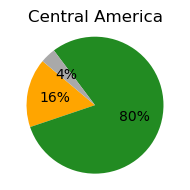

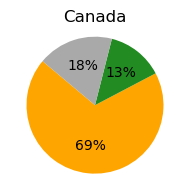

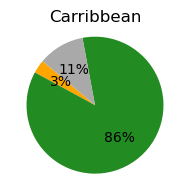

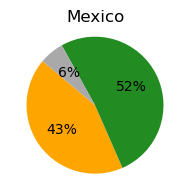

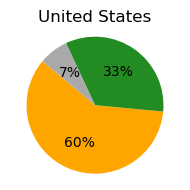

In [84]:
# Plot the proportional breakdown of priorLULC classes by area sum within each region as a pie chart. Use landuse_colors for colors. 
# For the sake of exporting, leave pie labels off the pie chart
for region in region_lulc_breakdown['naRegion'].unique():
    # Set region name
    if region == 'USA':
        region_name = 'United States'
    elif region == 'CAN':
        region_name = 'Canada'
    elif region == 'MEX':
        region_name = 'Mexico'
    elif region == 'CAR':
        region_name = 'Carribbean'
    elif region == 'CAM':
        region_name = 'Central America'
    region_data = region_lulc_breakdown[region_lulc_breakdown['naRegion'] == region]
    plt.figure(figsize=(2,2))
    plt.pie(region_data['proportion_km2'], labels=None, autopct='%1.0f%%', startangle=140, colors=[landuse_colors.get(lulc, 'grey') for lulc in region_data['priorLULC']])
    plt.title(f'{region_name}')
    plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
    plt.tight_layout()
    plt.savefig(os.path.join(figures_path, f'LULC_Breakdown_{region}.pdf'), dpi=300, bbox_inches='tight', pad_inches=0.1)
    plt.show()

## H3 Solar Density Plot

In [60]:
# Load data
arrays = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_LULC_final.shp'))
H3 = gpd.read_file(os.path.join(derivedTemp_path, r'NA_AOI_h3res4.shp'))

# Print number of arrays and H3 hexagons
print(f'Number of arrays: {len(arrays)}')
print(f'Number of H3 hexagons: {len(H3)}')

# Call AOI
aoi = gpd.read_file(aoiPath)
aoiDetailed = gpd.read_file(os.path.join(downloaded_path, r'NorthAmerica\NorthAmericaBoundary.shp'))

# Transform AOI's to toCRS
aoi = aoi.to_crs(toCRS)
aoiDetailed = aoiDetailed.to_crs(toCRS)

# Convert GMSEUS polygons to centroids
arrays['centroid'] = arrays.geometry.centroid
arrays_centroids = arrays.set_geometry('centroid')

# Add column to GMSEUS for counting
arrays_centroids['num'] = 1

# Set GMSEUS_centroids area to km2, and MWdc, round to 2 decimal places
arrays_centroids['area'] = (arrays_centroids['area'])# / 10**6).round(2)
arrays_centroids['capMWDC'] = arrays_centroids['capMWDC'].round(2)

# Select column to sum over
sumCol = 'num'

# Perform spatial join between CONUS_H3 and GMSEUS centroids
joined_gdf = gpd.sjoin(arrays_centroids[[sumCol, IDcol, 'centroid']], H3[['h3_index', 'geometry']], how='inner', predicate='intersects')

# Check if any points were missed, this is the case when using the masked H3 becuase some arrays are just outside the boundary
# If there are any missed points, assign them to the nearest hexagon
arrays_centroidsMissed = arrays_centroids[~arrays_centroids[IDcol].isin(joined_gdf[IDcol])].reset_index(drop=True)
if not arrays_centroidsMissed.empty:
    # sjoin_nearest uses the active geometry (centroids)
    nearest_gdf = gpd.sjoin_nearest(
        arrays_centroidsMissed[[sumCol, IDcol, 'centroid']],
        H3[['h3_index', 'geometry']],
        how='left',
        distance_col='dist_to_hex')  # keep if you want to inspect distances
    nearest_gdf = nearest_gdf.drop(columns='dist_to_hex')

    # Combine intersect- and nearest-based assignments ---
    joined_all = pd.concat([joined_gdf, nearest_gdf], ignore_index=True)

else:
    joined_all = joined_gdf

# Calculate sum of 'num' for each h3_index
sum_per_hexagon = joined_all.groupby('h3_index')[sumCol].sum().reset_index()

# Merge the sum data back into H3
H3 = H3.merge(sum_per_hexagon, on='h3_index', how='left')

# Fill NaN values with 0 if no points were found in a hexagon
H3['sum'] = H3[sumCol].fillna(0)

# Print sum of conus_h3 sum column
print(H3['sum'].sum())

Number of arrays: 25310
Number of H3 hexagons: 12057
25310.0


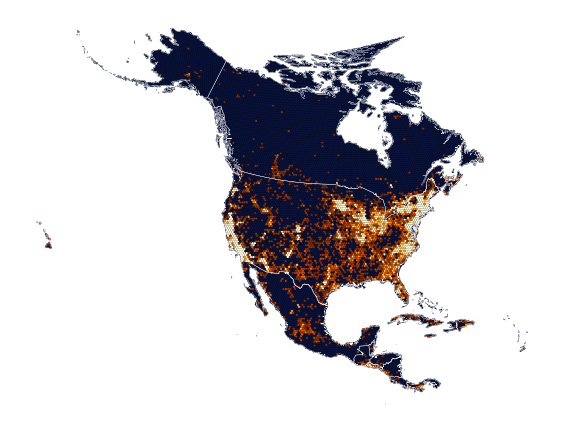

In [78]:
# Set no-solar color -- other blues: darker: noSolarCol = '#060D32', lighter: noSolarCol = '#0B1844'
noSolarCol = '#09133C'

# Define bounds automatically
values = H3['sum']
nonzero = values[values > 0] # Zero always gets its own bin
maxPercentile = nonzero.quantile(0.9) # Get 90% percentile to set as max

# Define a custom colormap: black for zero, then an orange-to-yellow gradient for 1 and above
cmap = mcolors.ListedColormap([noSolarCol] + plt.cm.YlOrBr(np.linspace(1, 0, 256)).tolist())
bounds = [0, 1] + list(range(2, int(maxPercentile)+1))  # Ensures values from 1 and up use the orange-yellow gradient
norm = mcolors.BoundaryNorm(bounds, cmap.N) # Define color boundaries: 0 maps to black, 1-20 maps to the orange-yellow gradient

# # Define bounds automatically
# values = H3['sum']
# nonzero = values[values > 0] # Zero always gets its own bin
# quantiles = nonzero.quantile([0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).tolist() # Define quantile breakpoints (you can adjust these)
# bounds = [0] + quantiles # Build bounds: 0, then these quantiles
# bounds.append(nonzero.max()) # Ensure max value is included
# cmap = mcolors.ListedColormap([noSolarCol] + plt.cm.YlOrBr(np.linspace(1, 0, len(bounds)-1)).tolist())
# norm = mcolors.BoundaryNorm(bounds, cmap.N)

# # Define a custom colormap: black for zero, then an orange-to-yellow gradient for 1 and above
# cmap = mcolors.ListedColormap([noSolarCol] + plt.cm.YlOrBr(np.linspace(1, 0, 256)).tolist())
# bounds = [0, 1] + list(range(2, 11))  # Ensures values from 1 and up use the orange-yellow gradient
# norm = mcolors.BoundaryNorm(bounds, cmap.N) # Define color boundaries: 0 maps to black, 1-20 maps to the orange-yellow gradient

# Plotting with the custom colormap
fig, ax = plt.subplots(1, 1, figsize=(7, 12))
aoi.plot(ax=ax, color='black', edgecolor='none', linewidth=0)
H3.plot(column='sum', cmap=cmap, linewidth=0.0, ax=ax, edgecolor='none', legend=False, norm=norm)
aoiDetailed.plot(ax=ax, color='none', edgecolor='white', linewidth=0.25)
aoi.plot(ax=ax, color='none', edgecolor=noSolarCol, linewidth=0.15)

# Turn off the axis
ax.set_axis_off()

# Export to figures
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_Hex.pdf'), dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_Hex.png'), dpi=300, bbox_inches='tight', pad_inches=0.1)

# Close the plot
plt.show()
plt.close()

### H3 Solar Density Histogram

## H3 Solar Food Plot

In [217]:
# Load data (colocated with final Caloric and Irrig offsets)
arrays = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_colocated_withKcalIrrig.shp'))
H3 = gpd.read_file(os.path.join(derivedTemp_path, r'NA_AOI_h3res4.shp'))

# Set DIV_BY for kcal to convert to billions of calories
DIV_BY = 1e9

# Select column to sum over
sumCol = 'totkcalYr'

# Print number of arrays and H3 hexagons
print(f'Number of arrays: {len(arrays)}')
print(f'Number of H3 hexagons: {len(H3)}')

# Call AOI
aoi = gpd.read_file(aoiPath)
aoiDetailed = gpd.read_file(os.path.join(downloaded_path, r'NorthAmerica\NorthAmericaBoundary.shp'))

# Transform AOI's to toCRS
aoi = aoi.to_crs(toCRS)
aoiDetailed = aoiDetailed.to_crs(toCRS)

# Convert GMSEUS polygons to centroids
arrays['centroid'] = arrays.geometry.centroid
arrays_centroids = arrays.set_geometry('centroid')

# Perform spatial join between CONUS_H3 and GMSEUS centroids
joined_gdf = gpd.sjoin(arrays_centroids[[sumCol, IDcol, 'centroid']], H3[['h3_index', 'geometry']], how='inner', predicate='intersects')

# Check if any points were missed, this is the case when using the masked H3 becuase some arrays are just outside the boundary
# If there are any missed points, assign them to the nearest hexagon
arrays_centroidsMissed = arrays_centroids[~arrays_centroids[IDcol].isin(joined_gdf[IDcol])].reset_index(drop=True)
if not arrays_centroidsMissed.empty:
    # sjoin_nearest uses the active geometry (centroids)
    nearest_gdf = gpd.sjoin_nearest(
        arrays_centroidsMissed[[sumCol, IDcol, 'centroid']],
        H3[['h3_index', 'geometry']],
        how='left',
        distance_col='dist_to_hex')  # keep if you want to inspect distances
    nearest_gdf = nearest_gdf.drop(columns='dist_to_hex')

    # Combine intersect- and nearest-based assignments ---
    joined_all = pd.concat([joined_gdf, nearest_gdf], ignore_index=True)

else:
    joined_all = joined_gdf

# Calculate sum of 'num' for each h3_index
sum_per_hexagon = joined_all.groupby('h3_index')[sumCol].sum().reset_index()

# Merge the sum data back into H3
H3 = H3.merge(sum_per_hexagon, on='h3_index', how='left')

# Print summary statistics of the sum column
print(H3[sumCol].describe())

Number of arrays: 11372
Number of H3 hexagons: 12057
count    2.007000e+03
mean     1.692655e+09
std      5.077193e+09
min      3.196954e+03
25%      1.169034e+07
50%      1.408241e+08
75%      9.741234e+08
max      7.204745e+10
Name: totkcalYr, dtype: float64


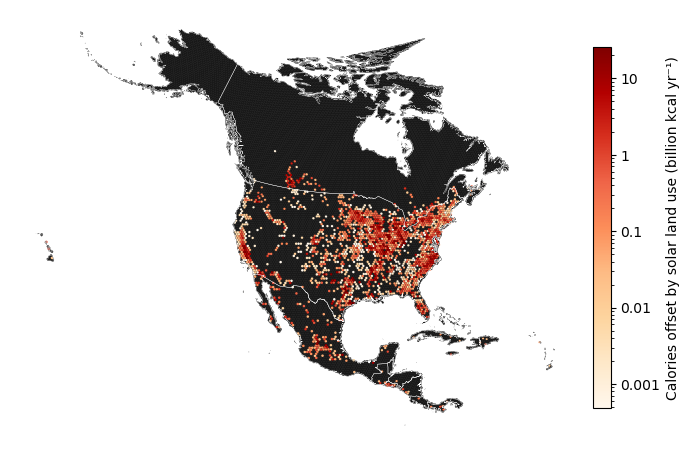

In [218]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

# ============================================================
# Universal settings
# ============================================================

# Set no solar color to almost black (dark dark grey)
noSolarCol = "#222222"
cmap = plt.cm.OrRd  # or plt.cm.Reds, plt.cm.RdPu
DIV_BY = 1e9        # 1e9 for "billions of kcal"; for km³ keep 1e9 if starting from m³
USE_LOG = True

# ============================================================
# Automated scaling helper
# ============================================================
def auto_vmin_vmax(values_pos, use_log=True, p_low=5, p_high=99, span_min_decades=2, safety=1.0):
    """
    values_pos: 1D array of positive values in *plot units* (already divided by DIV_BY)
    p_low/p_high: percentiles used to define the visible color range
    span_min_decades: ensures log span isn't too narrow (helps avoid flat maps)
    safety: multiplier on vmax if you want a tiny bit more headroom (e.g., 1.05)
    """
    v = np.asarray(values_pos, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        raise ValueError("No positive values to scale.")

    vmin = np.percentile(v, p_low)
    vmax = np.percentile(v, p_high) * safety

    # guard against pathological cases
    vmin = max(vmin, v.min())
    vmax = max(vmax, vmin * 1.01)

    if use_log:
        # if range is too narrow in log space, widen it a bit
        decades = np.log10(vmax) - np.log10(vmin)
        if decades < span_min_decades:
            target_vmin = vmax / (10 ** span_min_decades)
            vmin = max(target_vmin, v.min())

    return vmin, vmax

def nice_log_ticks(vmin, vmax, max_ticks=6):
    """Return nice log-spaced ticks between vmin and vmax."""
    lo = np.floor(np.log10(vmin))
    hi = np.ceil(np.log10(vmax))
    ticks = 10 ** np.arange(lo, hi + 1)

    ticks = ticks[(ticks >= vmin) & (ticks <= vmax)]
    if ticks.size > max_ticks:
        # downsample evenly if too many
        idx = np.linspace(0, len(ticks) - 1, max_ticks).round().astype(int)
        ticks = ticks[idx]
    return ticks

# ============================================================
# Prepare H3 plot values (zeros vs nonzero)
# ============================================================
plotCol = sumCol   # your summed hex column name
H3[plotCol] = H3[plotCol].fillna(0.0)
H3["plotVal"] = H3[plotCol] / DIV_BY

H3_zero = H3[H3["plotVal"] <= 0]
H3_pos  = H3[H3["plotVal"] > 0]

# ============================================================
# Automated vmin/vmax (tuned for your distribution)
# - p_low=5 avoids tiny near-zeros soaking the low end
# - p_high=99 clips the extreme tail (your max is ~72B kcal/yr)
# ============================================================
vmin, vmax = auto_vmin_vmax(H3_pos["plotVal"].values, use_log=USE_LOG, p_low=5, p_high=99, span_min_decades=3, safety=1.0)

norm = mcolors.LogNorm(vmin=vmin, vmax=vmax, clip=True) if USE_LOG else mcolors.Normalize(vmin=0, vmax=vmax, clip=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(7, 12))
ax.set_facecolor(noSolarCol)

aoi.plot(ax=ax, color="black", edgecolor="none", linewidth=0)
H3_zero.plot(ax=ax, color=noSolarCol, linewidth=0, edgecolor="none")
H3_pos.plot(column="plotVal", cmap=cmap, norm=norm, linewidth=0, edgecolor="none", ax=ax)

aoiDetailed.plot(ax=ax, color="none", edgecolor="white", linewidth=0.25)
aoi.plot(ax=ax, color="none", edgecolor=noSolarCol, linewidth=0.15)
ax.set_axis_off()

# ============================================================
# Colorbar with sensible ticks
# ============================================================
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)

if USE_LOG:
    ticks = nice_log_ticks(vmin, vmax, max_ticks=6)
    cbar.set_ticks(ticks)

# format ticks nicely (no scientific notation unless needed)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))

cbar.set_label("Calories offset by solar land use (billion kcal yr⁻¹)")

plt.tight_layout()
# plt.show()

# Export to figures
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_CaloricOffset_Hex.pdf'), dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_CaloricOffset_Hex.png'), dpi=300, bbox_inches='tight', pad_inches=0.1)
# plt.close()


## H3 Solar Water Plot

In [ ]:
# Load data (colocated with final Caloric and Irrig offsets)
arrays = gpd.read_file(os.path.join(derivedTemp_path, r'NA_arrays_colocated_withKcalIrrig.shp'))
H3 = gpd.read_file(os.path.join(derivedTemp_path, r'NA_AOI_h3res4.shp'))

# Set DIV_BY for kcal to convert to cubic kilometers
DIV_BY = 1e9

# Select column to sum over
sumCol = 'totm3Yr'

# Print number of arrays and H3 hexagons
print(f'Number of arrays: {len(arrays)}')
print(f'Number of H3 hexagons: {len(H3)}')

# Call AOI
aoi = gpd.read_file(aoiPath)
aoiDetailed = gpd.read_file(os.path.join(downloaded_path, r'NorthAmerica\NorthAmericaBoundary.shp'))

# Transform AOI's to toCRS
aoi = aoi.to_crs(toCRS)
aoiDetailed = aoiDetailed.to_crs(toCRS)

# Convert GMSEUS polygons to centroids
arrays['centroid'] = arrays.geometry.centroid
arrays_centroids = arrays.set_geometry('centroid')

# Perform spatial join between CONUS_H3 and GMSEUS centroids
joined_gdf = gpd.sjoin(arrays_centroids[[sumCol, IDcol, 'centroid']], H3[['h3_index', 'geometry']], how='inner', predicate='intersects')

# Check if any points were missed, this is the case when using the masked H3 becuase some arrays are just outside the boundary
# If there are any missed points, assign them to the nearest hexagon
arrays_centroidsMissed = arrays_centroids[~arrays_centroids[IDcol].isin(joined_gdf[IDcol])].reset_index(drop=True)
if not arrays_centroidsMissed.empty:
    # sjoin_nearest uses the active geometry (centroids)
    nearest_gdf = gpd.sjoin_nearest(
        arrays_centroidsMissed[[sumCol, IDcol, 'centroid']],
        H3[['h3_index', 'geometry']],
        how='left',
        distance_col='dist_to_hex')  # keep if you want to inspect distances
    nearest_gdf = nearest_gdf.drop(columns='dist_to_hex')

    # Combine intersect- and nearest-based assignments ---
    joined_all = pd.concat([joined_gdf, nearest_gdf], ignore_index=True)

else:
    joined_all = joined_gdf

# Calculate sum of 'num' for each h3_index
sum_per_hexagon = joined_all.groupby('h3_index')[sumCol].sum().reset_index()

# Merge the sum data back into H3
H3 = H3.merge(sum_per_hexagon, on='h3_index', how='left')

# Print summary statistics of the sum column
print(H3[sumCol].describe())

Number of arrays: 11372
Number of H3 hexagons: 12057
count    2.007000e+03
mean     4.671326e+08
std      1.728110e+09
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      9.664701e+07
max      2.858207e+10
Name: totmm3Yr, dtype: float64


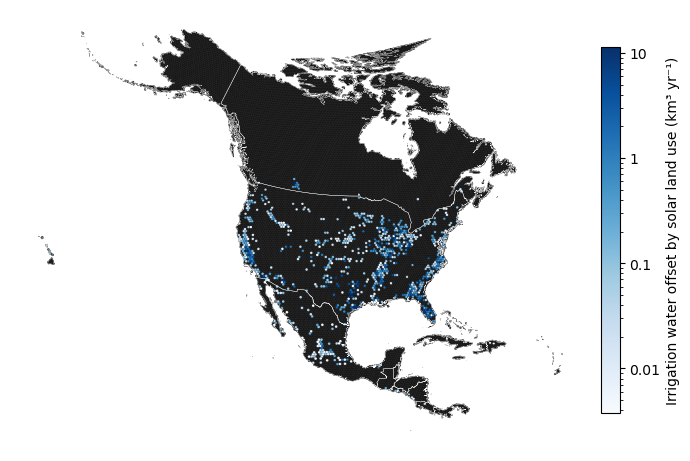

In [231]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

# ============================================================
# Universal settings
# ============================================================

# Set no solar color to almost black (dark dark grey)
noSolarCol = "#222222"
cmap = plt.cm.Blues  
DIV_BY = 1e9        # 1e9 for "billions of cubic meters"; for kcal keep 1e9 if starting from calories
USE_LOG = True

# ============================================================
# Automated scaling helper
# ============================================================
def auto_vmin_vmax(values_pos, use_log=True, p_low=5, p_high=99, span_min_decades=2, safety=1.0):
    """
    values_pos: 1D array of positive values in *plot units* (already divided by DIV_BY)
    p_low/p_high: percentiles used to define the visible color range
    span_min_decades: ensures log span isn't too narrow (helps avoid flat maps)
    safety: multiplier on vmax if you want a tiny bit more headroom (e.g., 1.05)
    """
    v = np.asarray(values_pos, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        raise ValueError("No positive values to scale.")

    vmin = np.percentile(v, p_low)
    vmax = np.percentile(v, p_high) * safety

    # guard against pathological cases
    vmin = max(vmin, v.min())
    vmax = max(vmax, vmin * 1.01)

    if use_log:
        # if range is too narrow in log space, widen it a bit
        decades = np.log10(vmax) - np.log10(vmin)
        if decades < span_min_decades:
            target_vmin = vmax / (10 ** span_min_decades)
            vmin = max(target_vmin, v.min())

    return vmin, vmax

def nice_log_ticks(vmin, vmax, max_ticks=6):
    """Return nice log-spaced ticks between vmin and vmax."""
    lo = np.floor(np.log10(vmin))
    hi = np.ceil(np.log10(vmax))
    ticks = 10 ** np.arange(lo, hi + 1)

    ticks = ticks[(ticks >= vmin) & (ticks <= vmax)]
    if ticks.size > max_ticks:
        # downsample evenly if too many
        idx = np.linspace(0, len(ticks) - 1, max_ticks).round().astype(int)
        ticks = ticks[idx]
    return ticks

# ============================================================
# Prepare H3 plot values (zeros vs nonzero)
# ============================================================
plotCol = sumCol   # your summed hex column name
H3[plotCol] = H3[plotCol].fillna(0.0)
H3["plotVal"] = H3[plotCol] / DIV_BY

H3_zero = H3[H3["plotVal"] <= 0]
H3_pos  = H3[H3["plotVal"] > 0]

# ============================================================
# Automated vmin/vmax (tuned for your distribution)
# - p_low=5 avoids tiny near-zeros soaking the low end
# - p_high=99 clips the extreme tail (your max is ~72B kcal/yr)
# ============================================================
vmin, vmax = auto_vmin_vmax(H3_pos["plotVal"].values, use_log=USE_LOG, p_low=5, p_high=99, span_min_decades=3, safety=1.0)

norm = mcolors.LogNorm(vmin=vmin, vmax=vmax, clip=True) if USE_LOG else mcolors.Normalize(vmin=0, vmax=vmax, clip=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(7, 12))
ax.set_facecolor(noSolarCol)

aoi.plot(ax=ax, color="black", edgecolor="none", linewidth=0)
H3_zero.plot(ax=ax, color=noSolarCol, linewidth=0, edgecolor="none")
H3_pos.plot(column="plotVal", cmap=cmap, norm=norm, linewidth=0, edgecolor="none", ax=ax)

aoiDetailed.plot(ax=ax, color="none", edgecolor="white", linewidth=0.25)
aoi.plot(ax=ax, color="none", edgecolor=noSolarCol, linewidth=0.15)
ax.set_axis_off()

# ============================================================
# Colorbar with sensible ticks
# ============================================================
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)

if USE_LOG:
    ticks = nice_log_ticks(vmin, vmax, max_ticks=6)
    cbar.set_ticks(ticks)

# format ticks nicely (no scientific notation unless needed)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))

cbar.set_label("Irrigation water offset by solar land use (km³ yr⁻¹)")

plt.tight_layout()
# plt.show()

# Export to figures
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_WaterOffset_Hex.pdf'), dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_WaterOffset_Hex.png'), dpi=300, bbox_inches='tight', pad_inches=0.1)
# plt.close()


# Get and plot area proportions through time

## Get proporational land use by area

In [7]:
# Aggregate proportions by instYr
instYr_landuse = lulc_grouped.groupby(['instYr', 'cdlLandUse'])['totArea'].sum().unstack(fill_value=0)

# Calculate proportions
instYr_landuse = instYr_landuse.div(instYr_landuse.sum(axis=1), axis=0)

# Compute total proportions for the entire dataset (for stacked bar chart)
total_landuse = lulc_grouped.groupby('cdlLandUse')['totArea'].sum()
total_landuse = total_landuse / total_landuse.sum()  # Normalize to proportions

# Define the correct order
landuse_order = ["Cropland", "Grassland and Pasture", "Natural", "Other LULC"]

# Reindex to ensure the order is correct and reorder instYr_landuse to match the total_landuse order
total_landuse = total_landuse.reindex(landuse_order, fill_value=0)
instYr_landuse = instYr_landuse.reindex(columns=landuse_order, fill_value=0)

# Define colors for stacked bar chart (same as area plot)
landuse_colors = {'Cropland': 'orange', 'Grassland and Pasture': 'gold', 'Natural': 'forestgreen', 'Other LULC': 'darkgrey'}

# Ensure colors are assigned in the correct order
ordered_colors = [landuse_colors[c] for c in total_landuse.index]

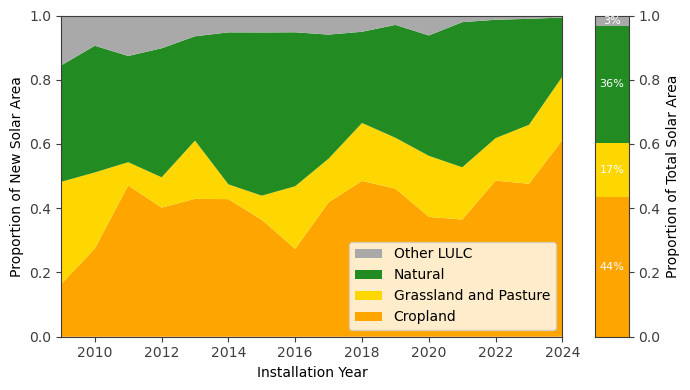

In [ ]:
# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(7, 4), gridspec_kw={'width_ratios': [15,1]})
#fig, axes = plt.subplots(1, 2, figsize=(2.5, 1.3), gridspec_kw={'width_ratios': [15,1]})

# Plot proportional area over time
instYr_landuse.plot(kind='area', stacked=True, ax=axes[0], color=[landuse_colors[c] for c in instYr_landuse.columns], linewidth=0)
axes[0].set_xlabel("Installation Year", fontsize=10, color='black')
axes[0].set_ylabel("Proportion of New Solar Area", fontsize=10, color='black')
axes[0].set_xlim(2009, 2024)
axes[0].set_ylim(0, 1)  # Keep Y-axis strictly within 0-1

# Flip the order of the legend, set title to None, and set legend border to none
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles[::-1], labels[::-1], title=None)

# Plot the single proportional stacked bar chart on the separate axis
bottoms = [sum(total_landuse[:i]) for i in range(len(total_landuse))]
axes[1].bar(x=[0], height=1, width=0.5, color=ordered_colors, bottom=bottoms)

# Add proportion labels at the center of each color section
for i, (prop, color) in enumerate(zip(total_landuse, ordered_colors)):
    center = bottoms[i] + prop / 2
    axes[1].text(0, center, f"{round(prop * 100)}%", ha='center', va='center', fontsize=8, color='white')

# Plot the single proportional stacked bar chart on the separate axis
axes[1].set_ylim(0, 1)
axes[1].set_xlim(-0.25, 0.25)  # Set x-axis limits to center the bar
axes[1].set_xticks([])
axes[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[1].yaxis.tick_right()  # Move y-axis ticks to the right
axes[1].yaxis.set_label_position('right')  # Move y-axis label to the right
axes[1].set_ylabel('Proportion of Total Solar Area', fontsize=10, color='black')  # Add y-axis label on the right
axes[1].set_frame_on(True)
axes[1].margins(0, 0)

# Set axis text to be darkgreytheme
axes[0].tick_params(axis='x', colors=darkGreyTheme)
axes[0].tick_params(axis='y', colors=darkGreyTheme)
axes[1].tick_params(axis='x', colors=darkGreyTheme)
axes[1].tick_params(axis='y', colors=darkGreyTheme)

# Set frame color to darkgreytheme
axes[0].spines['top'].set_color(darkGreyTheme)
axes[0].spines['bottom'].set_color(darkGreyTheme)
axes[0].spines['left'].set_color(darkGreyTheme)
axes[0].spines['right'].set_color(darkGreyTheme)
axes[1].spines['top'].set_color(darkGreyTheme)
axes[1].spines['bottom'].set_color(darkGreyTheme)
axes[1].spines['left'].set_color(darkGreyTheme)
axes[1].spines['right'].set_color(darkGreyTheme)

# Show and export
plt.tight_layout()
fig.savefig(os.path.join(figures_path, r'ProportionalNewLandUseOverTime.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(figures_path, r'ProportionalNewLandUseOverTime.pdf'), dpi=300, bbox_inches='tight')
plt.show()

## Get proportional land use by number

In [9]:
# Aggregate proportions by number of arrays
instYr_landuse = lulc_grouped.groupby(['instYr', 'cdlLandUse'])['arrayID'].count().unstack(fill_value=0)

# Calculate proportions
instYr_landuse = instYr_landuse.div(instYr_landuse.sum(axis=1), axis=0)

# Compute total proportions for the entire dataset (for pie chart)
total_landuse = lulc_grouped.groupby('cdlLandUse')['arrayID'].count()
total_landuse = total_landuse / total_landuse.sum()  # Normalize to proportions

# Define the correct order
landuse_order = ["Cropland", "Grassland and Pasture", "Natural", "Other LULC"]

# Reindex to ensure the order is correct and reorder instYr_landuse to match the total_landuse order
total_landuse = total_landuse.reindex(landuse_order, fill_value=0)
instYr_landuse = instYr_landuse.reindex(columns=landuse_order, fill_value=0)

# Define colors for pie chart (same as area plot)
landuse_colors = {'Cropland': 'orange', 'Grassland and Pasture': 'gold', 'Natural': 'forestgreen', 'Other LULC': 'darkgrey'}

# Ensure colors are assigned in the correct order
ordered_colors = [landuse_colors[c] for c in total_landuse.index]

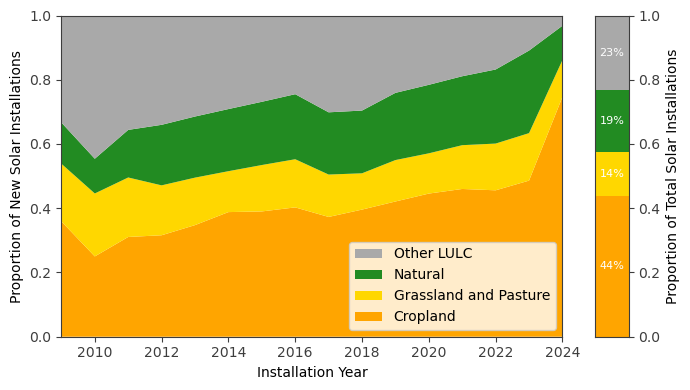

In [10]:
# Set up the figure
fig, axes = plt.subplots(1, 2, figsize=(7, 4), gridspec_kw={'width_ratios': [15,1]})

# Plot proportional area over time
instYr_landuse.plot(kind='area', stacked=True, ax=axes[0], color=[landuse_colors[c] for c in instYr_landuse.columns], linewidth=0)
axes[0].set_xlabel("Installation Year", fontsize=10, color='black')
axes[0].set_ylabel("Proportion of New Solar Installations", fontsize=10, color='black')
axes[0].set_xlim(2009, 2024)
axes[0].set_ylim(0, 1)  # Keep Y-axis strictly within 0-1

# Flip the order of the legend, set title to None, and set legend border to none
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles[::-1], labels[::-1], title=None)

# Plot the single proportional stacked bar chart on the separate axis
bottoms = [sum(total_landuse[:i]) for i in range(len(total_landuse))]
axes[1].bar(x=[0], height=1, width=0.5, color=ordered_colors, bottom=bottoms)

# Add proportion labels at the center of each color section
for i, (prop, color) in enumerate(zip(total_landuse, ordered_colors)):
    center = bottoms[i] + prop / 2
    axes[1].text(0, center, f"{round(prop * 100)}%", ha='center', va='center', fontsize=8, color='white')

# Plot the single proportional stacked bar chart on the separate axis
axes[1].set_ylim(0, 1)
axes[1].set_xlim(-0.25, 0.25)  # Set x-axis limits to center the bar
axes[1].set_xticks([])
axes[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[1].yaxis.tick_right()  # Move y-axis ticks to the right
axes[1].yaxis.set_label_position('right')  # Move y-axis label to the right
axes[1].set_ylabel('Proportion of Total Solar Installations', fontsize=10, color='black')  # Add y-axis label on the right
axes[1].set_frame_on(True)
axes[1].margins(0, 0)

# Set axis text to be darkgreytheme
axes[0].tick_params(axis='x', colors=darkGreyTheme)
axes[0].tick_params(axis='y', colors=darkGreyTheme)
axes[1].tick_params(axis='x', colors=darkGreyTheme)
axes[1].tick_params(axis='y', colors=darkGreyTheme)

# Set frame color to darkgreytheme
axes[0].spines['top'].set_color(darkGreyTheme)
axes[0].spines['bottom'].set_color(darkGreyTheme)
axes[0].spines['left'].set_color(darkGreyTheme)
axes[0].spines['right'].set_color(darkGreyTheme)
axes[1].spines['top'].set_color(darkGreyTheme)
axes[1].spines['bottom'].set_color(darkGreyTheme)
axes[1].spines['left'].set_color(darkGreyTheme)
axes[1].spines['right'].set_color(darkGreyTheme)

# Show and export
plt.tight_layout()
fig.savefig(os.path.join(figures_path, r'ProportionalNewLandUseOverTime_arrays.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(figures_path, r'ProportionalNewLandUseOverTime_arrays.pdf'), dpi=300, bbox_inches='tight')
plt.show()

## Draw with gridded logic
[Grid Motivation](https://www.google.com/search?client=firefox-b-1-e&channel=entpr&q=State+grid+political+map+&sei=W4O3Z9H2ObirptQP7ajpoQ4#imgrc=T7Pe9f0aA9puhM&imgdii=YfdHQuUXFMbWZM)

In [39]:
# Define an 8-row × 11-column grid layout for states
state_grid = {
    # Row 1
    'ME': (0, 10),  
    # Row 2
    'WI': (1, 5), 'VT': (1, 9), 'NH': (1, 10),  
    # Row 3
    'WA': (2, 0), 'ID': (2, 1), 'MT': (2, 2), 'ND': (2, 3), 'MN': (2, 4), 
    'IL': (2, 5), 'MI': (2, 6), 'NY': (2, 8), 'MA': (2, 9),
    # Row 4
    'OR': (3, 0), 'NV': (3, 1), 'WY': (3, 2), 'SD': (3, 3), 'IA': (3, 4), 
    'IN': (3, 5), 'OH': (3, 6), 'PA': (3, 7), 'NJ': (3, 8), 'CT': (3, 9), 'RI': (3, 10),
    # Row 5
    'CA': (4, 0), 'UT': (4, 1), 'CO': (4, 2), 'NE': (4, 3), 'MO': (4, 4), 
    'KY': (4, 5), 'WV': (4, 6), 'VA': (4, 7), 'MD': (4, 8), 'DE': (4, 9), 
    # Row 6 (first column empty)
    'AZ': (5, 1), 'NM': (5, 2), 'KS': (5, 3), 'AR': (5, 4), 'TN': (5, 5), 
    'NC': (5, 6), 'SC': (5, 7), 'DC': (5, 8),
    # Row 7 (first three columns empty)
    'OK': (6, 3), 'LA': (6, 4), 'MS': (6, 5), 'AL': (6, 6), 'GA': (6, 7),
    # Row 8 (first four columns empty, 6th and 7th columns empty)
    'TX': (7, 4), 'FL': (7, 8)}

# Define STATEFP to state abbreviation mapping
state_abbreviation_map = {
    '01': 'AL', '04': 'AZ', '05': 'AR', '06': 'CA', '08': 'CO', '09': 'CT', '10': 'DE', '11': 'DC', '12': 'FL', '13': 'GA', 
    '16': 'ID', '17': 'IL', '18': 'IN', '19': 'IA', '20': 'KS', '21': 'KY', '22': 'LA', '23': 'ME', '24': 'MD', '25': 'MA', 
    '26': 'MI', '27': 'MN', '28': 'MS', '29': 'MO', '30': 'MT', '31': 'NE', '32': 'NV', '33': 'NH', '34': 'NJ', '35': 'NM', 
    '36': 'NY', '37': 'NC', '38': 'ND', '39': 'OH', '40': 'OK', '41': 'OR', '42': 'PA', '44': 'RI', '45': 'SC', '46': 'SD',
    '47': 'TN', '48': 'TX', '49': 'UT', '50': 'VT', '51': 'VA', '53': 'WA', '54': 'WV', '55': 'WI', '56': 'WY'}

# States with polinator scorecard (Florida, Illinois, Indiana, Maryland, Massachusetts, Michigan, Minnesota, Missouri, North Carolina, Caifornia, Oregon, Ohio, South Carolina, Vermont, Virgina, Wisconsin)
state_pollinator_scorecard = {'FL', 'IL', 'IN', 'MD', 'MA', 'MI', 'MN', 'MO', 'NC', 'OR', 'OH', 'SC', 'VT', 'VA', 'WI'} # 'CA',

# Step 1: Compute total land area before normalization
state_total_area = lulc_grouped.groupby('STATEFP')['totArea'].sum().divide(1e6).reset_index()

# Step 2: Define radius based on total area
def get_radius(total_area):
    if total_area < 10:
        return 0.25
    elif total_area <= 100:
        return 0.375
    else:
        return 0.50

# Aggregate total area for each land use type by state
state_landuse = lulc_grouped.groupby(['STATEFP', 'cdlLandUse'])['totArea'].sum().unstack(fill_value=0)

# Save a df to check out the land use areas
state_landuse_AreaCheck = state_landuse.copy()

# Normalize each state's land use to proportions (so they sum to 1)
state_landuse = state_landuse.div(state_landuse.sum(axis=1), axis=0)

# Map STATEFP to state abbreviations
state_landuse['State'] = state_landuse.index.map(state_abbreviation_map)

# Remove states not found in the mapping (e.g., territories like PR)
state_landuse = state_landuse.dropna(subset=['State']).reset_index()

# Save a df to check out the land use areas
state_landuse_PropCheck = state_landuse_AreaCheck.copy()

# Convert to dictionary with state abbreviations as keys
state_landuse_data = state_landuse.set_index('State').to_dict(orient='index')

# Define colors for each land use class
landuse_colors = {'Cropland': 'orange', 'Grassland and Pasture': 'gold', 'Natural': 'forestgreen', 'Other LULC': 'darkgrey'}

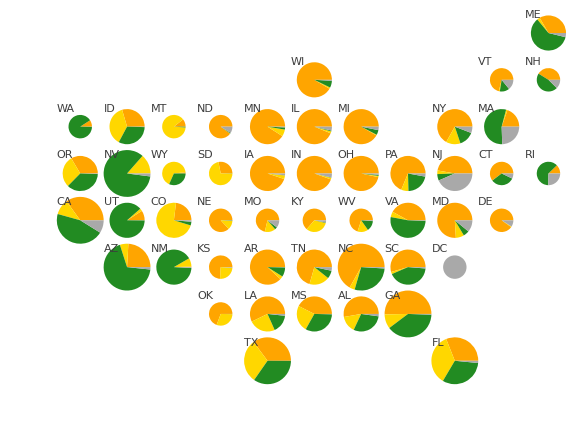

In [ ]:
# Create figure
fig, ax = plt.subplots(figsize=(7.25, 7.25))

# Plot each state as a tile (square) with a pie chart
for state, (row, col) in state_grid.items():
    # # If state is a pollinator scorecard state, set a light gray box
    # if state in state_pollinator_scorecard:
    #     ax.add_patch(plt.Rectangle((col, -row), 1, 1, color='lightgrey', ec='none', lw=1))
    #     pass
    # else:
    #     #ax.add_patch(plt.Rectangle((col, -row), 1, 1, color='white', ec='black', lw=1))
    #     pass

    # Define centroid of the tile for pie chart
    x, y = col + 0.5, -row + 0.5

    # Get state abbreviation and total area
    state_fp = next((fp for fp, abbr in state_abbreviation_map.items() if abbr == state), None)
    total_area = state_total_area[state_total_area['STATEFP'] == state_fp]['totArea'].values[0] if state_fp else 0
    radius = get_radius(total_area)  # Determine pie chart radius

    # Retrieve land use data for the state, drop STATEFP
    landuse_data = state_landuse_data[state].copy()
    landuse_data.pop('STATEFP')

    wedges, texts, autotexts = ax.pie(
        landuse_data.values(),
        colors=[landuse_colors[c] for c in landuse_data.keys()],
        center=(x, y),
        radius=radius,
        wedgeprops={'edgecolor': 'white', 'linewidth': 0.0},
        labels=None,  
        autopct=lambda p: ''  # This keeps three outputs but hides text
    )

    # Add state abbreviation in the upper-left corner of the tile
    ax.text(col + 0.00, -row + 1.00, state, ha='left', va='top', fontsize=8, color=darkGreyTheme, fontweight='normal')

# Formatting the grid
ax.set_xlim(-1, 11)
ax.set_ylim(-8, 1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect('equal')
ax.set_frame_on(False)
#plt.show()

# Export as png and pdf
fig.savefig(os.path.join(figures_path, 'stateLandUsePie.png'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(figures_path, 'stateLandUsePie.pdf'), dpi=300, bbox_inches='tight')


# Get and plot FUT PVR values across space and stats

In [13]:
# Define an 8-row × 11-column grid layout for states
state_grid = {
    # Row 1
    'ME': (0, 10),  
    # Row 2
    'WI': (1, 5), 'VT': (1, 9), 'NH': (1, 10),  
    # Row 3
    'WA': (2, 0), 'ID': (2, 1), 'MT': (2, 2), 'ND': (2, 3), 'MN': (2, 4), 
    'IL': (2, 5), 'MI': (2, 6), 'NY': (2, 8), 'MA': (2, 9),
    # Row 4
    'OR': (3, 0), 'NV': (3, 1), 'WY': (3, 2), 'SD': (3, 3), 'IA': (3, 4), 
    'IN': (3, 5), 'OH': (3, 6), 'PA': (3, 7), 'NJ': (3, 8), 'CT': (3, 9), 'RI': (3, 10),
    # Row 5
    'CA': (4, 0), 'UT': (4, 1), 'CO': (4, 2), 'NE': (4, 3), 'MO': (4, 4), 
    'KY': (4, 5), 'WV': (4, 6), 'VA': (4, 7), 'MD': (4, 8), 'DE': (4, 9), 
    # Row 6 (first column empty)
    'AZ': (5, 1), 'NM': (5, 2), 'KS': (5, 3), 'AR': (5, 4), 'TN': (5, 5), 
    'NC': (5, 6), 'SC': (5, 7), 'DC': (5, 8),
    # Row 7 (first three columns empty)
    'OK': (6, 3), 'LA': (6, 4), 'MS': (6, 5), 'AL': (6, 6), 'GA': (6, 7),
    # Row 8 (first four columns empty, 6th and 7th columns empty)
    'TX': (7, 4), 'FL': (7, 8)}

# Define STATEFP to state abbreviation mapping
state_abbreviation_map = {
    '01': 'AL', '04': 'AZ', '05': 'AR', '06': 'CA', '08': 'CO', '09': 'CT', '10': 'DE', '11': 'DC', '12': 'FL', '13': 'GA', 
    '16': 'ID', '17': 'IL', '18': 'IN', '19': 'IA', '20': 'KS', '21': 'KY', '22': 'LA', '23': 'ME', '24': 'MD', '25': 'MA', 
    '26': 'MI', '27': 'MN', '28': 'MS', '29': 'MO', '30': 'MT', '31': 'NE', '32': 'NV', '33': 'NH', '34': 'NJ', '35': 'NM', 
    '36': 'NY', '37': 'NC', '38': 'ND', '39': 'OH', '40': 'OK', '41': 'OR', '42': 'PA', '44': 'RI', '45': 'SC', '46': 'SD',
    '47': 'TN', '48': 'TX', '49': 'UT', '50': 'VT', '51': 'VA', '53': 'WA', '54': 'WV', '55': 'WI', '56': 'WY'}

# States with polinator scorecard (Florida, Illinois, Indiana, Maryland, Massachusetts, Michigan, Minnesota, Missouri, North Carolina, Caifornia, Oregon, Ohio, South Carolina, Vermont, Virgina, Wisconsin)
state_pollinator_scorecard = {'FL', 'IL', 'IN', 'MD', 'MA', 'MI', 'MN', 'MO', 'NC', 'OR', 'OH', 'SC', 'VT', 'VA', 'WI'} # 'CA',

# Define radius based on total area
def get_radius(total_area):
    if total_area == 0:
        return 0
    elif total_area < 10:
        return 0.25
    elif total_area <= 100:
        return 0.375
    else:
        return 0.50

# Set arrays path
arraysPath = r'S:\Users\stidjaco\R_files\SolarLandscapes\Data\Derived\intermediateProducts\GMSEUS_Arrays_LULC.shp'

# Set FUT PVR CSV location
FUT_PVR_basePath = r'S:\Users\stidjaco\R_files\BigPanel\Data\Derived\intermediateProducts\AFT_FUT_PVR_results'

# Call arrays
arrays = gpd.read_file(arraysPath)

# Call and combine all csv files in FUT_PVR_basePath
all_files = [f for f in os.listdir(FUT_PVR_basePath) if f.endswith('.csv')]
df_list = []
for file in all_files:
    df = pd.read_csv(os.path.join(FUT_PVR_basePath, file))
    df_list.append(df)
pvr = pd.concat(df_list, ignore_index=True)

# Select only necessary columns from arrays
arrays_subset = arrays[['arrayID', 'capMW', 'STATEFP', 'geometry']].copy()

# Add all attributes from pvr to arrays based on arrayID, and drop any rows not in pvr
arraysPVR = arrays_subset.merge(pvr, on='arrayID', how='left')
arraysPVR = arraysPVR.dropna(subset=['solPVRsig']).reset_index(drop=True)

# Drop rows with solPVRsig <= 0
arraysPVR = arraysPVR[arraysPVR['solPVRsig'] > 0].reset_index(drop=True)

# Set totArea as solArea
arraysPVR['totArea'] = arraysPVR['solArea']

# Export arraysPVR to shapefile
arraysPVR.to_file(os.path.join(derivedTemp_path, r'arrays_withFUT_PVR.shp'))

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Print summary stats

# Print sum of totArea in arraysPVR
print(f'Total area in arraysPVR: {arraysPVR["totArea"].sum() / 1e6:.2f} km²')

# Print sum of solPVRsig in arraysPVR
print(f'Total solPVRsig in arraysPVR: {arraysPVR["solPVRsig"].sum() / 1e6:.2f} km²')

# Print summary stats of solPVRpSig column
print(arraysPVR['solPVRsig'].describe())

# # Check some errors for WA (issue with totArea not maching solArea)
# wa_arraysPVR = arraysPVR[arraysPVR['STATEFP'] == '53'].reset_index(drop=True)
# print(wa_arraysPVR['solPVRsig'].describe())
# print(wa_arraysPVR['totArea'].describe())
# print(wa_arraysPVR['solPVRpSig'].describe())
# wa_arraysPVR = wa_arraysPVR.drop(columns='geometry')

C:\Users\stidjaco\AppData\Local\Temp\ipykernel_34860\3634803300.py:77: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  arraysPVR.to_file(os.path.join(derivedTemp_path, r'arrays_withFUT_PVR.shp'))


Total area in arraysPVR: 1541.62 km²
Total solPVRsig in arraysPVR: 969.10 km²
count    6.269000e+03
mean     1.545867e+05
std      6.049377e+05
min      2.000000e+00
25%      6.743000e+03
50%      2.394500e+04
75%      6.424900e+04
max      1.142378e+07
Name: solPVRsig, dtype: float64


In [111]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Nationally Significant PVR Land (binary)

# Compute total land area before normalization
state_total_area = arraysPVR.groupby('STATEFP')['totArea'].sum().divide(1e6).reset_index()

# If a state from state_grid is missing in state_total_area, add it with 0 area
for state in state_grid.keys():
    state_fp = next((fp for fp, abbr in state_abbreviation_map.items() if abbr == state), None)
    if state_fp and state_fp not in state_total_area['STATEFP'].values:
        new_row = {'STATEFP': state_fp, 'totArea': 0.0}
        state_total_area = pd.concat([state_total_area, pd.DataFrame([new_row])], ignore_index=True)

# Create a new df called pvrSig with STATEFP and set totArea to solPVRsig. Set a new column called "PVR Class" to "Nationally Significant PVR"
pvrSig = arraysPVR[['STATEFP', 'solPVRsig']].copy()
pvrSig = pvrSig.rename(columns={'solPVRsig': 'totArea'})
pvrSig['PVR Class'] = 'Nationally Significant PVR Land'

# Create a new df called pvrNotSig with STATEFP and set totArea to totArea - solPVRsig. Set a new column called "PVR Class" to "Not Nationally Significant PVR"
pvrNotSig = arraysPVR[['STATEFP', 'totArea', 'solPVRsig']].copy()
pvrNotSig['totArea'] = pvrNotSig['totArea'] - pvrNotSig['solPVRsig']
pvrNotSig = pvrNotSig[['STATEFP', 'totArea']]
pvrNotSig['PVR Class'] = 'Not Nationally Significant PVR Land'

# Combine pvrSig and pvrNotSig into a new df called pvrCombined
pvrCombined = pd.concat([pvrSig, pvrNotSig], ignore_index=True)

# Aggregate total area for each land use type by state
state_pvr = pvrCombined.groupby(['STATEFP', 'PVR Class'])['totArea'].sum().unstack(fill_value=0)

# Save a df to check out the land use areas
state_pvr_AreaCheck = state_pvr.copy()

# Normalize each state's land use to proportions (so they sum to 1)
state_pvr = state_pvr.div(state_pvr.sum(axis=1), axis=0)

# Map STATEFP to state abbreviations
state_pvr['State'] = state_pvr.index.map(state_abbreviation_map)

# Remove states not found in the mapping (e.g., territories like PR)
state_pvr = state_pvr.dropna(subset=['State']).reset_index()

# If a state from state_grid is missing in state_pvr, add it with 0 proportions
for state in state_grid.keys():
    if state not in state_pvr['State'].values:
        # Pull STATEFP from state_abbreviation_map
        new_row = {'STATEFP': next((fp for fp, abbr in state_abbreviation_map.items() if abbr == state), None), 'Nationally Significant PVR Land': 0.0, 'Not Nationally Significant PVR Land': 1.0, 'State': state}
        state_pvr = pd.concat([state_pvr, pd.DataFrame([new_row])], ignore_index=True)

# Save a df to check out the land use areas
state_pvr_PropCheck = state_pvr_AreaCheck.copy()

# Convert to dictionary with state abbreviations as keys
state_pvr_data = state_pvr.set_index('State').to_dict(orient='index')

# Define colors for each land use class
pvr_colors = {'Nationally Significant PVR Land': '#1F4E79', 'Not Nationally Significant PVR Land': "#CF7C2F"} 

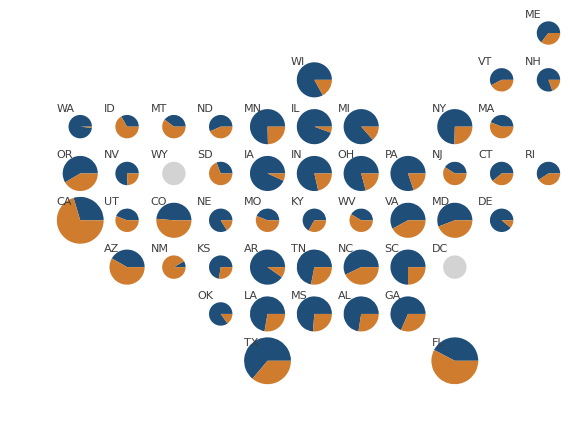

In [113]:
# Create figure
fig, ax = plt.subplots(figsize=(7.25, 7.25))

# Plot each state as a tile (square) with a pie chart
for state, (row, col) in state_grid.items():
    # Define centroid of the tile for pie chart
    x, y = col + 0.5, -row + 0.5

    # Get state abbreviation and total area
    state_fp = next((fp for fp, abbr in state_abbreviation_map.items() if abbr == state), None)
    total_area = state_total_area[state_total_area['STATEFP'] == state_fp]['totArea'].values[0] if state_fp else 0
    radius = get_radius(total_area)  # Determine pie chart radius

    # If total_area is > 0, plot pie chart, else plot an empty pie chart (skip)
    if total_area > 0: 

        # Retrieve land use data for the state, drop STATEFP
        pvr_data = state_pvr_data[state].copy()
        pvr_data.pop('STATEFP')

        wedges, texts, autotexts = ax.pie(
            pvr_data.values(),
            colors=[pvr_colors[c] for c in pvr_data.keys()],
            center=(x, y),
            radius=radius,
            wedgeprops={'edgecolor': 'white', 'linewidth': 0.0},
            labels=None,  
            autopct=lambda p: '')  # This keeps three outputs but hides text

        # Add state abbreviation in the upper-left corner of the tile
        ax.text(col + 0.00, -row + 1.00, state, ha='left', va='top', fontsize=8, color=darkGreyTheme, fontweight='normal')
    
    # Else, just add the state abbreviation in the upper-left corner of the tile and a small empty pie chart of size where total_area < 10
    else:
        radius = get_radius(5)  # Small radius for empty pie chart
        wedges, texts, autotexts = ax.pie(
            [1],  # Single slice to represent empty pie
            colors=['#d3d3d3'],  # Light grey color for empty pie
            center=(x, y),
            radius=radius,
            wedgeprops={'edgecolor': 'white', 'linewidth': 0.0},
            labels=None,
            autopct=lambda p: '')  # Hide text
        ax.text(col + 0.00, -row + 1.00, state, ha='left', va='top', fontsize=8, color=darkGreyTheme, fontweight='normal')

# Formatting the grid
ax.set_xlim(-1, 11)
ax.set_ylim(-8, 1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect('equal')
ax.set_frame_on(False)
plt.show()


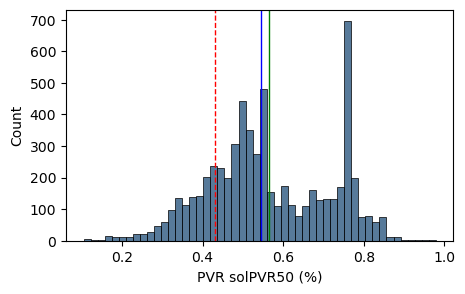

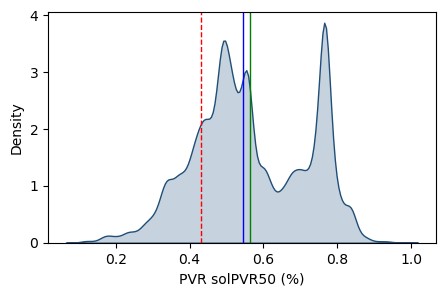

In [128]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set metric
pvrMetric = 'solPVR50'

# Set arraysPVRdist, and drop rows where solPVR50 is -9999
arraysPVRdist = arraysPVR.copy()
arraysPVRdist = arraysPVRdist[arraysPVRdist[pvrMetric] != -9999].reset_index(drop=True)

# Use a distribution plot to plot the distribution of solPVR50 values from arraysPVRdist
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.histplot(arraysPVRdist[pvrMetric], bins=50, kde=False, color='#1F4E79', edgecolor='black', ax=ax)
ax.set_xlabel(f'PVR {pvrMetric} (%)', color='black') 

# Add a vertical red line at x=0.43
ax.axvline(x=0.43, color='red', linestyle='--', linewidth=1)

# Plot mean and median lines
mean_value = arraysPVRdist[pvrMetric].mean()
median_value = arraysPVRdist[pvrMetric].median()
ax.axvline(x=mean_value, color='green', linestyle='-', linewidth=1, label='Mean')
ax.axvline(x=median_value, color='blue', linestyle='-', linewidth=1, label='Median')

# Make a new plot that is a curve not a histogram
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.kdeplot(arraysPVRdist[pvrMetric], bw_adjust=0.5, fill=True, color='#1F4E79', ax=ax)
ax.set_xlabel(f'PVR {pvrMetric} (%)', color='black')

# Add a vertical red line at x=0.43
ax.axvline(x=0.43, color='red', linestyle='--', linewidth=1)
# Plot mean and median lines
ax.axvline(x=mean_value, color='green', linestyle='-', linewidth=1, label='Mean')
ax.axvline(x=median_value, color='blue', linestyle='-', linewidth=1, label='Median')

f:\Python_Envs\BigPanel\Lib\site-packages\numpy\core\_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


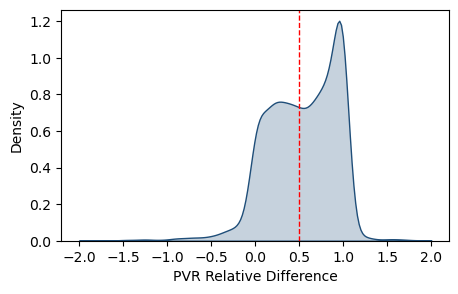

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set metric
pvrMetric = 'solPVR50'
pvrFldMetric = 'fldPVR50'

# Set arraysPVRdist, and drop rows where metrics are -9999
arraysPVRrel = arraysPVR.copy()
arraysPVRrel = arraysPVRrel[arraysPVRrel[pvrMetric] != -9999].reset_index(drop=True)
arraysPVRrel = arraysPVRrel[arraysPVRrel[pvrFldMetric] != -9999].reset_index(drop=True)

# Get a new metric which is. 
arraysPVRrel['relPVRme'] = (arraysPVRrel[pvrMetric] - arraysPVRrel['fldPVR10']) / (arraysPVRrel['fldPVR90'] - arraysPVRrel['fldPVR10'])

# Make a new plot that is a curve not a histogram, limit plot from 0.5 to 1.5
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.kdeplot(arraysPVRrel['relPVRme'], bw_adjust=0.5, fill=True, color='#1F4E79', ax=ax, clip=(-2, 2.0))
ax.set_xlabel('PVR Relative Difference', color='black')

# Add a vertical red line at x=0.43
ax.axvline(x=0.5, color='red', linestyle='--', linewidth=1)

# Add line that is plot median
median_relPVRme = arraysPVRrel['relPVRme'].mean()
ax.axvline(x=median_relPVRme, color='green', linestyle='--', linewidth=1)

## H3 Solar PVR Plot

In [27]:
# Load data (colocated with final Caloric and Irrig offsets)
arrays = gpd.read_file(os.path.join(derivedTemp_path, r'arrays_withFUT_PVR.shp'))
H3 = gpd.read_file(os.path.join(derivedTemp_path, r'NA_AOI_h3res4.shp'))

# Set arrays toCRS (already defined)
arrays = arrays.to_crs(toCRS)

# Set tmpArrID column that is arrayID
arrays['tmpArrID'] = arrays['arrayID']

# Set DIV_BY for kcal to convert to cubic kilometers
DIV_BY = 1

# Set mathematical operation
MATH_OP = 'MEAN'  # Options: 'SUM', 'MEAN', 'MEDIAN', 'MODE', 'MAX', 'MIN'

# Select column to sum over
columnOfInterest = 'solPVRpSig'  # Column in arrays to sum over H3 hexagons

# Drop rows with -9999 in columnOfInterest
arrays = arrays[arrays[columnOfInterest] != -9999].reset_index(drop=True)

# Print number of arrays and H3 hexagons
print(f'Number of arrays: {len(arrays)}')
print(f'Number of H3 hexagons: {len(H3)}')

# Call AOI
aoi = gpd.read_file(aoiPath)
aoiDetailed = gpd.read_file(os.path.join(downloaded_path, r'NorthAmerica\NorthAmericaBoundary.shp'))

# Transform AOI's to toCRS
aoi = aoi.to_crs(toCRS)
aoiDetailed = aoiDetailed.to_crs(toCRS)

# Convert GMSEUS polygons to centroids
arrays['centroid'] = arrays.geometry.centroid
arrays_centroids = arrays.set_geometry('centroid')

# Perform spatial join between CONUS_H3 and GMSEUS centroids
joined_gdf = gpd.sjoin(arrays_centroids[[columnOfInterest, IDcol, 'centroid']], H3[['h3_index', 'geometry']], how='inner', predicate='intersects')

# Check if any points were missed, this is the case when using the masked H3 becuase some arrays are just outside the boundary
# If there are any missed points, assign them to the nearest hexagon
arrays_centroidsMissed = arrays_centroids[~arrays_centroids[IDcol].isin(joined_gdf[IDcol])].reset_index(drop=True)
if not arrays_centroidsMissed.empty:
    # sjoin_nearest uses the active geometry (centroids)
    nearest_gdf = gpd.sjoin_nearest(
        arrays_centroidsMissed[[columnOfInterest, IDcol, 'centroid']],
        H3[['h3_index', 'geometry']],
        how='left',
        distance_col='dist_to_hex')  # keep if you want to inspect distances
    nearest_gdf = nearest_gdf.drop(columns='dist_to_hex')

    # Combine intersect- and nearest-based assignments ---
    joined_all = pd.concat([joined_gdf, nearest_gdf], ignore_index=True)

else:
    joined_all = joined_gdf

# Calculate the math-operation value for each h3_index
if MATH_OP == 'SUM':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].sum().reset_index()
elif MATH_OP == 'MEAN':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].mean().reset_index()
elif MATH_OP == 'MEDIAN':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].median().reset_index()
elif MATH_OP == 'MODE':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan).reset_index()
elif MATH_OP == 'MAX':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].max().reset_index()
elif MATH_OP == 'MIN':
    sum_per_hexagon = joined_all.groupby('h3_index')[columnOfInterest].min().reset_index()

# Merge the sum data back into H3
H3 = H3.merge(sum_per_hexagon, on='h3_index', how='left')

# Print summary statistics of the sum column
print(H3[columnOfInterest].describe())

Number of arrays: 6269
Number of H3 hexagons: 12057
count    1222.000000
mean        0.667646
std         0.284105
min         0.000000
25%         0.487750
50%         0.721600
75%         0.923700
max         1.015100
Name: solPVRpSig, dtype: float64


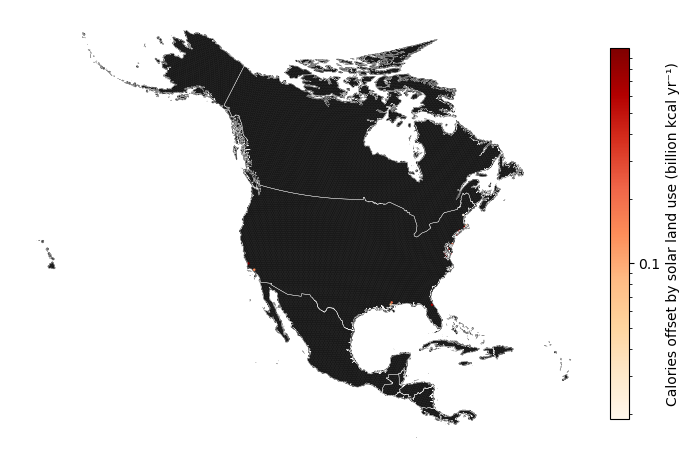

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter

# ============================================================
# Universal settings
# ============================================================

# Set no solar color to almost black (dark dark grey)
noSolarCol = "#222222"
cmap = plt.cm.OrRd  # or plt.cm.Reds, plt.cm.RdPu
DIV_BY = 1       # 1e9 for "billions of kcal"; for km³ keep 1e9 if starting from m³
USE_LOG = False

# ============================================================
# Automated scaling helper
# ============================================================
def auto_vmin_vmax(values_pos, use_log=True, p_low=5, p_high=99, span_min_decades=2, safety=1.0):
    """
    values_pos: 1D array of positive values in *plot units* (already divided by DIV_BY)
    p_low/p_high: percentiles used to define the visible color range
    span_min_decades: ensures log span isn't too narrow (helps avoid flat maps)
    safety: multiplier on vmax if you want a tiny bit more headroom (e.g., 1.05)
    """
    v = np.asarray(values_pos, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        raise ValueError("No positive values to scale.")

    vmin = np.percentile(v, p_low)
    vmax = np.percentile(v, p_high) * safety

    # guard against pathological cases
    vmin = max(vmin, v.min())
    vmax = max(vmax, vmin * 1.01)

    if use_log:
        # if range is too narrow in log space, widen it a bit
        decades = np.log10(vmax) - np.log10(vmin)
        if decades < span_min_decades:
            target_vmin = vmax / (10 ** span_min_decades)
            vmin = max(target_vmin, v.min())

    return vmin, vmax

def nice_log_ticks(vmin, vmax, max_ticks=6):
    """Return nice log-spaced ticks between vmin and vmax."""
    lo = np.floor(np.log10(vmin))
    hi = np.ceil(np.log10(vmax))
    ticks = 10 ** np.arange(lo, hi + 1)

    ticks = ticks[(ticks >= vmin) & (ticks <= vmax)]
    if ticks.size > max_ticks:
        # downsample evenly if too many
        idx = np.linspace(0, len(ticks) - 1, max_ticks).round().astype(int)
        ticks = ticks[idx]
    return ticks

# ============================================================
# Prepare H3 plot values (zeros vs nonzero)
# ============================================================
plotCol = columnOfInterest   # your summed hex column name
H3[plotCol] = H3[plotCol].fillna(0.0)
H3["plotVal"] = H3[plotCol] / DIV_BY

H3_zero = H3[H3["plotVal"] <= 0]
H3_pos  = H3[H3["plotVal"] > 0]

# ============================================================
# Automated vmin/vmax (tuned for your distribution)
# - p_low=5 avoids tiny near-zeros soaking the low end
# - p_high=99 clips the extreme tail (your max is ~72B kcal/yr)
# ============================================================
vmin, vmax = auto_vmin_vmax(H3_pos["plotVal"].values, use_log=USE_LOG, p_low=5, p_high=99, span_min_decades=3, safety=1.0)

norm = mcolors.LogNorm(vmin=vmin, vmax=vmax, clip=True) if USE_LOG else mcolors.Normalize(vmin=0, vmax=vmax, clip=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(7, 12))
ax.set_facecolor(noSolarCol)

aoi.plot(ax=ax, color="black", edgecolor="none", linewidth=0)
H3_zero.plot(ax=ax, color=noSolarCol, linewidth=0, edgecolor="none")
H3_pos.plot(column="plotVal", cmap=cmap, norm=norm, linewidth=0, edgecolor="none", ax=ax)

aoiDetailed.plot(ax=ax, color="none", edgecolor="white", linewidth=0.25)
aoi.plot(ax=ax, color="none", edgecolor=noSolarCol, linewidth=0.15)
ax.set_axis_off()

# ============================================================
# Colorbar with sensible ticks
# ============================================================
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)

if USE_LOG:
    ticks = nice_log_ticks(vmin, vmax, max_ticks=6)
    cbar.set_ticks(ticks)

# format ticks nicely (no scientific notation unless needed)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))

cbar.set_label("Calories offset by solar land use (billion kcal yr⁻¹)")

plt.tight_layout()
plt.show()

# # Export to figures
# plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_CaloricOffset_Hex.pdf'), dpi=300, bbox_inches='tight', pad_inches=0.1)
# plt.savefig(os.path.join(figures_path, 'NorthAmerica_Arrays_CaloricOffset_Hex.png'), dpi=300, bbox_inches='tight', pad_inches=0.1)
# # plt.close()
